In [1]:
prefix = "blackspot_black"

In [2]:
!pip install pymoo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.7/72.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.3/328.3 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.9/866.9 kB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 3.3 MB/s eta 0:00:00


In [3]:
import gdown
from google.colab import drive

from tensorflow.keras.models import load_model

import torch
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2

from PIL import Image

import numpy as np

from skimage.segmentation import slic, mark_boundaries

from itertools import product

import random

import copy

import matplotlib.pyplot as plt

from pymoo.indicators.hv import HV

import plotly.express as px
import pandas as pd

import cv2

from google.colab import files

# Data and Model Preparation

In [4]:
#drive.mount('/content/drive')

In [5]:
# !mkdir -p /content/citrus_leaf_diseases

# !cp -r "/content/drive/MyDrive/CLD" "/content/citrus_leaf_diseases"

In [6]:
# dataset = ImageFolder(root='/content/citrus_leaf_diseases/CLD')

# paths = [s[0] for s in dataset.samples]
# labels = [s[1] for s in dataset.samples]

In [7]:
# rand_idx = 225
# rand_img = v2.Resize((256, 256))(Image.open(paths[rand_idx]).convert('RGB'))
# true_label = labels[rand_idx]
# np_img = np.asarray(rand_img)
# print("True label:", true_label)
# plt.imshow(np_img)
# plt.show()

In [8]:
def download_file_from_drive(file_id, output_name):
    url = f'https://drive.google.com/uc?id={file_id}'

    gdown.download(url, output_name, quiet=False)

In [9]:
download_file_from_drive(file_id="1FLMNdePqRR-JtIS9aHx_43wBimnXIwZo",
                         output_name="plantUpsampled4.weights.best.hdf5")
download_file_from_drive(file_id="1aTL3qrV_IkWHdZcJZdJ3R0akLiOFBNkh",
                         output_name="X1_test.npy")
download_file_from_drive(file_id="1LBSo_qbn00C3eSthkQYp_HuOojX46ZW2",
                         output_name="y1_test.npy")

Downloading...
From (original): https://drive.google.com/uc?id=1FLMNdePqRR-JtIS9aHx_43wBimnXIwZo
From (redirected): https://drive.google.com/uc?id=1FLMNdePqRR-JtIS9aHx_43wBimnXIwZo&confirm=t&uuid=7f39dd2e-962e-4476-a903-68c09f92fe13
To: /content/plantUpsampled4.weights.best.hdf5
100%|██████████| 284M/284M [00:07<00:00, 38.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1aTL3qrV_IkWHdZcJZdJ3R0akLiOFBNkh
To: /content/X1_test.npy
100%|██████████| 46.4M/46.4M [00:00<00:00, 85.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1LBSo_qbn00C3eSthkQYp_HuOojX46ZW2
To: /content/y1_test.npy
100%|██████████| 1.07k/1.07k [00:00<00:00, 3.61MB/s]


In [10]:
!wget https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/image5_delineated.npy -O image5_delineated.npy

!wget https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/worst5.npy -O worst5.npy

--2026-07-10 02:29:16--  https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/image5_delineated.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 786560 (768K) [application/octet-stream]
Saving to: ‘image5_delineated.npy’

image5_delineated.n 100%[===================>] 768.12K  --.-KB/s    in 0.03s   

2026-07-10 02:29:16 (27.4 MB/s) - ‘image5_delineated.npy’ saved [786560/786560]

--2026-07-10 02:29:16--  https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/worst5.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request se

In [11]:
groundtruth = np.load("image5_delineated.npy")
worst = np.load("worst5.npy")

In [12]:
model = load_model('plantUpsampled4.weights.best.hdf5')
x_test = np.load('X1_test.npy')
y_test = np.load('y1_test.npy')

/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


In [13]:
def make_blackbox_func(model):

  def get_probability_vector(image_input):
    if len(image_input.shape) == 3:
        image_input = np.expand_dims(image_input, axis=0)

    probability_vector = model.predict(image_input, verbose=0)

    return probability_vector

  return get_probability_vector

predict_func = make_blackbox_func(model)

# MOGAE

In [14]:
class CandidateSolution:
    def __init__(self, Chromosome, class_to_explain, predict, image, superpixels, mask_color):
        # model, transforms, interested_cls
        self.Chromosome = Chromosome
        self.n_as = Chromosome.sum().item()
        self.Image = self.from_chromosome_to_image(Chromosome, image, superpixels, mask_color)

        probs = predict(self.Image)[0]
        pred_cls = int(np.argmax(probs))

        self.ValidAcc = (pred_cls == class_to_explain)

        self.Pred = probs[class_to_explain]
        num_sp = len(Chromosome)
        self.Fitness = np.array([(num_sp - self.n_as + 1) / (num_sp), self.Pred])

        self.Rank = None
        self.DominationSet = None
        self.DominatedCount = None
        self.CrowdingDistance = None


    def from_chromosome_to_image(self, chromosome, image, superpixels, mask_color):

        activated_superpixels = np.where(chromosome == 1)[0]
        mask = np.isin(superpixels, activated_superpixels)
        masked_image = image.copy()
        masked_image[~mask] = mask_color

        return masked_image

In [15]:
def dominates(a, b):
    return np.all(a.Fitness >= b.Fitness) and np.any(a.Fitness > b.Fitness)

def BTS(Pop):
    """
        Binary Tournament Selection.
    """
    x1, x2 = random.sample(Pop, 2)
    if x1.Rank < x2.Rank:
        return x1
    elif x2.Rank < x1.Rank:
        return x2
    elif x1.CrowdingDistance > x2.CrowdingDistance:
        return x1
    else: return x2

In [16]:
def apply_box_blur_to_superpixels(image, superpixels, selected_superpixels, blurred_image):

    mask_2d = np.isin(superpixels, selected_superpixels)
    mask_3d = mask_2d[..., np.newaxis]

    result_image = np.where(mask_3d, blurred_image, image)

    return result_image

def apply_black_color_to_superpixels(image, superpixels, selected_superpixels):
    black_image = np.zeros_like(image)

    mask_2d = np.isin(superpixels, selected_superpixels)
    mask_3d = mask_2d[..., np.newaxis]

    result_image = np.where(mask_3d, black_image, image)

    return result_image

def calculate_insertion_metric(superpixels, chromosome, original_image, baseline, predict, class_to_explain):
    """
        P_original - P_insertion
    """
    unselected_superpixels = np.where(chromosome == 0)[0]

    if baseline == "black":
        inserted_image = apply_black_color_to_superpixels(original_image, superpixels, unselected_superpixels)
    elif baseline == "blur":
        blurred_img = cv2.GaussianBlur(original_image, (11, 11), 0)
        inserted_image = apply_box_blur_to_superpixels(original_image, superpixels, unselected_superpixels, blurred_img)
    else:
        raise ValueError("Invalid baseline")

    input_original = np.expand_dims(original_image, axis=0)
    input_insertion = np.expand_dims(inserted_image, axis=0)

    p_original = predict(input_original)[0][class_to_explain]
    p_insertion = predict(input_insertion)[0][class_to_explain]

    insertion_score = p_original - p_insertion

    return insertion_score.item() #, p_original, p_insertion, inserted_image


def calculate_deletion_metric(superpixels, chromosome, original_image, baseline, predict, class_to_explain):
    """
        P_original - P_deletion
    """
    selected_superpixels = np.where(chromosome == 1)[0]

    if baseline == "black":
        deleted_image = apply_black_color_to_superpixels(original_image, superpixels, selected_superpixels)
    elif baseline == "blur":
        blurred_img = cv2.GaussianBlur(original_image, (11, 11), 0)
        deleted_image = apply_box_blur_to_superpixels(original_image, superpixels, selected_superpixels, blurred_img)
    else:
        raise ValueError("Invalid baseline")

    input_original = np.expand_dims(original_image, axis=0)
    input_deletion = np.expand_dims(deleted_image, axis=0)

    p_original = predict(input_original)[0][class_to_explain]
    p_deletion = predict(input_deletion)[0][class_to_explain]

    deletion_score = p_original - p_deletion

    return deletion_score.item() #, p_original, p_deletion, deleted_image


def compute_IoU_metric(MV_image, groundtruth):
    mv_arr = np.array(MV_image)
    gt_arr = np.array(groundtruth)

    if mv_arr.shape != gt_arr.shape:
        raise ValueError("Incompatible image size")

    if len(mv_arr.shape) == 3:
        mv_mask = np.any(mv_arr != 0, axis=-1)
        gt_mask = np.any(gt_arr != 0, axis=-1)
    else:
        mv_mask = mv_arr != 0
        gt_mask = gt_arr != 0

    intersection = np.logical_and(mv_mask, gt_mask).sum()

    union = np.logical_or(mv_mask, gt_mask).sum()

    if union == 0:
        return 1.0

    iou = intersection / union
    return iou.item()


def compute_normalized_error(calculated, actual, worst):
    error = np.sqrt(np.sum(np.square(actual.reshape(-1) - calculated.reshape(-1))))

    max_error = np.sqrt(np.sum(np.square(actual.reshape(-1) - worst.reshape(-1))))

    normalized_error = (error / max_error).item()
    return normalized_error


In [17]:
class MOGAE_Explainer:
    def __init__(self, predict, image, class_to_explain, mask_color=[0, 0, 0]):
        # interested_cls
        self.class_to_explain = class_to_explain

        # Systematic search attributes
        self.base_image = None
        self.base_perturbation = None
        self.base_superpixels = None

        # Model (forward) attributes
        self.predict = predict

        # Image attributes
        self.image = image
        self.superpixels = None
        self.num_sp = None
        self.MV_solution = None
        self.explanatory_image = None
        self.mask_color = mask_color

        # Algorithm attributes
        self.max_iter = None
        self.nPop = None
        self.nPopc = None
        self.nPopm = None
        self.Pop = None
        self.Fronts = None
        self.ParetoFront = None
        self.yhat = None
        self.TagCheck = None
        self.TagFlag = None
        self.Omega = None
        self.delta = None
        self.theta_previous = None
        self.theta_current = None
        self.best_PF = None
        self.best_theta = None
        self.history_gen = None
        self.history_hv = None

        self.black_insertion_scores = []
        self.black_deletion_scores = []
        self.blur_insertion_scores = []
        self.blur_deletion_scores = []
        self.iou_scores = []
        self.normalized_errors = []

        self.y = self.predict(image)[0][class_to_explain].item()


    def run(self, verbose=False):

        self.systematic_search(verbose=verbose)

        self.segmentation(verbose=verbose)

        self.optimization(verbose=verbose)

        self.generate_MV_image(verbose=verbose)

        self.generate_explanatory_image(verbose=verbose)


    def systematic_search(self, h=5, alpha=0.2, beta=0.8, verbose=False):

        self.base_image = None
        self.base_perturbation = None
        self.base_superpixels = slic(self.image, n_segments=h, start_label=0)
        best = 0
        num_sp = self.base_superpixels.max().item() + 1
        t = np.array(list(product([0, 1], repeat=num_sp)))
        for i in range(len(t)):
            n_as = t[i].sum().item()

            # mask image
            activated_superpixels = np.where(t[i] == 1)[0]
            mask = np.isin(self.base_superpixels, activated_superpixels)
            masked_image = self.image.copy()
            masked_image[~mask] = self.mask_color

            # forward and compute fitness
            probs = self.predict(masked_image)[0]
            yhat = probs[self.class_to_explain].item()
            top_class = np.argmax(probs).item()

            if n_as == 0:
                fit = 0.7 * yhat
            else:
                fit = alpha * ((num_sp - n_as + 1)/num_sp) + beta * yhat

            # find best perturbation
            if fit > best and top_class == self.class_to_explain:
                best = fit
                self.base_image = masked_image
                self.base_perturbation = t[i].copy()

        if verbose:
          fig, ax = plt.subplots(1, 2, figsize=(10, 5))

          ax[0].imshow(mark_boundaries(self.image, self.base_superpixels))
          ax[0].set_title("Segmented image")
          ax[0].axis("off")

          ax[1].imshow(self.base_image)
          ax[1].set_title("Base image")
          ax[1].axis("off")

          plt.tight_layout()
          plt.show()
          print()


    def segmentation(self, H=50, verbose=False):
        self.superpixels = slic(self.image, n_segments=H, start_label=0)
        self.num_sp = self.superpixels.max().item() + 1

        if verbose:
            plt.imshow(mark_boundaries(self.image, self.superpixels))
            plt.title(f"Segmentation result\nNumber of superpixels: {self.num_sp}")
            plt.axis("off")
            plt.tight_layout()
            plt.show()
            print()


    def plot_paretofront(self):
        dominated_sparsities = [p.Fitness[0] for p in self.Pop if p.Rank > 1]
        dominated_predictions = [p.Fitness[1] for p in self.Pop if p.Rank > 1]

        pareto_sparsities = [p.Fitness[0] for p in self.ParetoFront]
        pareto_predictions = [p.Fitness[1] for p in self.ParetoFront]

        plt.figure(figsize=(8, 6))

        plt.scatter(
            dominated_sparsities,
            dominated_predictions,
            c='lightgray',
            alpha=0.6,
            edgecolors='none',
            s=30,
            label='Dominated Solutions'
        )

        plt.scatter(
            pareto_sparsities,
            pareto_predictions,
            c='teal',
            alpha=0.8,
            edgecolors='black',
            s=70,
            label='Pareto Front'
        )

        plt.xlabel('Sparsity', fontsize=12)
        plt.ylabel('Prediction', fontsize=12)

        plt.xlim(-0.05, 1.05)
        plt.ylim(-0.05, 1.05)

        plt.legend(loc='lower left', framealpha=0.9, fontsize=10)

        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()


    def optimization(self, verbose=False):
        self.TagCheck = 1
        self.TagFlag = 1

        self.black_insertion_scores = []
        self.black_deletion_scores = []
        self.blur_insertion_scores = []
        self.blur_deletion_scores = []
        self.iou_scores = []
        self.normalized_errors = []

        self.Pop_initialization(verbose)

        self.nondominated_sorting()
        self.crowding_distance()
        self.sorting()

        self.plot_paretofront()

        self.generate_MV_image(verbose=verbose)

        self.theta_current = self.y / (self.yhat + 1e-10)
        self.theta_previous = self.theta_current

        # For hypervolume visualization
        ref_point = np.array([0.05, 0.05])
        hv_calculator = HV(ref_point=ref_point)
        self.history_gen = []
        self.history_hv = []

        for it in range(self.max_iter):
            Popc = self.crossover()

            Popm = self.adaptive_mutation()

            self.Pop = self.Pop + Popc + Popm

            self.nondominated_sorting()
            self.crowding_distance()
            self.sorting()

            self.theta_current = self.y / (self.yhat + 1e-10)
            self.update_Tags()
            self.theta_previous = self.theta_current

            # Compute insertion/deletion score for black and blur baseline
            chromosome = self.generate_MV_image(verbose=False)
            black_insertion_score = calculate_insertion_metric(self.superpixels, chromosome, self.image, "black", self.predict, self.class_to_explain)
            black_deletion_score = calculate_deletion_metric(self.superpixels, chromosome, self.image, "black", self.predict, self.class_to_explain)
            blur_insertion_score = calculate_insertion_metric(self.superpixels, chromosome, self.image, "blur", self.predict, self.class_to_explain)
            blur_deletion_score = calculate_deletion_metric(self.superpixels, chromosome, self.image, "blur", self.predict, self.class_to_explain)

            self.black_insertion_scores.append(black_insertion_score)
            self.black_deletion_scores.append(black_deletion_score)
            self.blur_insertion_scores.append(blur_insertion_score)
            self.blur_deletion_scores.append(blur_deletion_score)

            # Compute IoU score
            iou_score = compute_IoU_metric(self.MV_solution.Image, groundtruth)
            self.iou_scores.append(iou_score)

            # Compute normalized error
            normalized_error = compute_normalized_error(self.MV_solution.Image, groundtruth, worst)
            self.normalized_errors.append(normalized_error)


            # For hypervolume visualization
            if (it + 1) % 10 == 0 or it == 0:
                # Get objectives arrays and multiply with -1
                obj1 = -1*np.array([p.Fitness[0] for p in self.ParetoFront])
                obj2 = -1*np.array([p.Fitness[1] for p in self.ParetoFront])

                obj1 = np.reshape(obj1, (-1, 1))
                obj2 = np.reshape(obj2, (-1, 1))

                # Compute Hypervolume
                F = np.hstack((obj1, obj2))
                current_hv = hv_calculator.do(F)

                self.history_gen.append(it+1)
                self.history_hv.append(current_hv)

                if verbose:
                    print(f"Hypervolume at {it+1}th iteration: {current_hv:.4f}")

            # Visualization every 10 iterations
            if verbose:
                if (it + 1) % 10 == 0:

                    # Visualization of some solutions in Pareto Front
                    n = min(5, len(self.ParetoFront))

                    if n > 0:
                        some_solutions = self.ParetoFront[:n]

                        fig, ax = plt.subplots(1, n, figsize=(15, 5))

                        if n == 1:
                            ax = [ax]

                        for i in range(n):
                            ax[i].imshow(some_solutions[i].Image)
                            sparsity = some_solutions[i].Fitness[0].item()
                            prediction = some_solutions[i].Fitness[1].item()
                            validity = some_solutions[i].ValidAcc
                            ax[i].set_title(f"Sparsity: {sparsity:.4f}\nPrediction: {prediction:.6f}\nValidity: {validity}")
                            ax[i].axis('off')

                        plt.suptitle(f"Some solutions in Pareto Front iter {it+1}/{self.max_iter}", fontsize=16, y=0.95)
                        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
                        plt.show()
                        print("Pareto Front size:", len(self.ParetoFront))

                    # Visualization of Pareto Front
                    self.plot_paretofront()

                    # Visualize MV image
                    self.generate_MV_image(verbose=verbose)

        # Hypervolume visualization
        if verbose:
            self.plot_hypervolume()


    def plot_hypervolume(self):
        if self.history_gen is not None:
            plt.figure(figsize=(8, 5))
            plt.plot(self.history_gen, self.history_hv, marker='o', linestyle='-', color='b')
            plt.xlabel("Iteration")
            plt.ylabel("Hypervolume")
            plt.title("Convergence of Hypervolume")
            plt.grid("True")
            plt.show()
            print()


    def generate_MV_image(self, verbose=False):
        optimal_chromosomes = []
        seen_chromosomes = set()

        # Remove duplicates and ValidAcc==0
        for p in self.ParetoFront:
            if p.ValidAcc:
                chrom_tuple = tuple(p.Chromosome)
                if chrom_tuple not in seen_chromosomes:
                    optimal_chromosomes.append(p.Chromosome)
                    seen_chromosomes.add(chrom_tuple)

        # Majority voting on best valid solutions
        MV_chromosome = self.majority_voting(optimal_chromosomes)
        self.MV_solution = CandidateSolution(MV_chromosome, self.class_to_explain,
                                             self.predict, self.image,
                                             self.superpixels, self.mask_color)

        if verbose:
            fig, ax = plt.subplots(1, 2, figsize=(10, 5))

            ax[0].imshow(self.MV_solution.Image)
            ax[0].set_title("MV image")
            ax[0].axis('off')

            ax[1].imshow(self.image)
            ax[1].set_title("Original image")
            ax[1].axis('off')

            plt.tight_layout()
            plt.show()
            print()

        return MV_chromosome


    def generate_explanatory_image(self, verbose=False):
        mask1 = self.base_perturbation[self.base_superpixels]
        mask2 = self.MV_solution.Chromosome[self.superpixels]
        intersection_mask = np.logical_and(mask1, mask2)

        result_image = self.image.copy()
        result_image[~intersection_mask] = self.mask_color

        self.explanatory_image = result_image

        if verbose:
          fig, ax = plt.subplots(1, 3, figsize=(15, 5))

          ax[0].imshow(self.MV_solution.Image)
          ax[0].set_title("MV image")
          ax[0].axis('off')

          ax[1].imshow(self.base_image)
          ax[1].set_title("Base image")
          ax[1].axis('off')

          ax[2].imshow(self.explanatory_image)
          ax[2].set_title("Explanatory image")
          ax[2].axis('off')

          plt.tight_layout()
          plt.show()
          print()


    def set_optimization_hyperparameters(self, nPop=35, crossover_prob=0.9,
                                         mutation_prob=0.4, max_iter=100,
                                         Omega=0.5, delta=0.2):
        self.nPop = nPop
        self.nPopc = int(2 * np.ceil(crossover_prob * (self.nPop/2)).item())
        self.nPopm = int(np.ceil(mutation_prob * self.nPop).item())
        self.max_iter = max_iter
        self.Omega = Omega
        self.delta = delta


    def Pop_initialization(self, verbose):
        Chromosomes = np.random.choice([0, 1], size=(self.nPop, self.num_sp)).astype(np.uint8)
        self.Pop = [CandidateSolution(Chromosomes[i], self.class_to_explain,
                                      self.predict, self.image, self.superpixels,
                                      self.mask_color)
                   for i in range(self.nPop)]
        if verbose:
            fig, ax = plt.subplots(1, 5, figsize=(15, 5))
            candidate_solutions = self.Pop[:5]
            for i in range(5):
                ax[i].imshow(candidate_solutions[i].Image)
                sparsity = candidate_solutions[i].Fitness[0].item()
                prediction = candidate_solutions[i].Fitness[1].item()
                validity = candidate_solutions[i].ValidAcc
                ax[i].set_title(f"Sparsity: {sparsity:.4f}\nPrediction: {prediction:.6f}\nValidity: {validity}")
                ax[i].axis('off')

            plt.suptitle("Some initialized solutions", fontsize=16, y=0.95)
            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.show()
            print()


    def nondominated_sorting(self):
        for p in self.Pop:
            p.DominationSet = []
            p.DominatedCount = 0

        self.Fronts = dict()
        self.Fronts[1] = []

        for i in range(len(self.Pop)):
            for j in range(i+1, len(self.Pop)):
                if dominates(self.Pop[i], self.Pop[j]):
                    self.Pop[i].DominationSet.append(j)
                    self.Pop[j].DominatedCount += 1
                elif dominates(self.Pop[j], self.Pop[i]):
                    self.Pop[j].DominationSet.append(i)
                    self.Pop[i].DominatedCount += 1
            if self.Pop[i].DominatedCount == 0:
                self.Pop[i].Rank = 1
                self.Fronts[1].append(i)

        k = 1
        while True:
            Q = []
            for i in self.Fronts[k]:
                for j in self.Pop[i].DominationSet:
                    self.Pop[j].DominatedCount -= 1
                    if self.Pop[j].DominatedCount == 0:
                        Q.append(j)
                        self.Pop[j].Rank = k + 1
            if len(Q) == 0: break
            self.Fronts[k+1] = Q
            k += 1


    def crowding_distance(self):
        for layer in self.Fronts.keys():
            current_layer = self.Fronts[layer]
            h = len(current_layer)
            if h == 0: continue

            CD = np.zeros(h)
            nObj = len(self.Pop[0].Fitness)

            for j in range(nObj):
                fitness_values = [self.Pop[i].Fitness[j] for i in current_layer]
                order = np.argsort(fitness_values)
                CD[order[0]] = np.inf
                CD[order[-1]] = np.inf
                f_max = fitness_values[order[-1]]
                f_min = fitness_values[order[0]]
                f_range = f_max - f_min + 1e-10

                for i in range(1, h-1):
                    neighbor1_value = fitness_values[order[i - 1]]
                    neighbor2_value = fitness_values[order[i + 1]]
                    CD[order[i]] += (neighbor2_value - neighbor1_value) / f_range

            for idx in range(h):
                self.Pop[current_layer[idx]].CrowdingDistance = CD[idx]


    def sorting(self):
        self.Pop.sort(key=lambda x: x.CrowdingDistance, reverse=True)
        self.Pop.sort(key=lambda x: x.Rank, reverse=False)

        self.Pop = self.Pop[:self.nPop]
        self.ParetoFront = [p for p in self.Pop if p.Rank == 1]

        yhats = [p.Pred for p in self.ParetoFront]
        self.yhat = max(yhats)


    def SPC(self):
        x1 = BTS(self.Pop)
        x2 = BTS(self.Pop)

        C = random.randint(1, self.num_sp - 1)

        z1 = np.concatenate((x1.Chromosome[:C], x2.Chromosome[C:]))
        z2 = np.concatenate((x2.Chromosome[:C], x1.Chromosome[C:]))

        return CandidateSolution(z1, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels, self.mask_color), \
               CandidateSolution(z2, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels, self.mask_color)


    def crossover(self):
        Popc = []
        while len(Popc) < self.nPopc:
            Popc += self.SPC()

        return Popc


    def adaptive_mutation(self):

        Popm = []

        if self.theta_current > 3:
            if self.TagCheck == 10:
                self.Omega += self.delta * (1 - self.Omega)
                Popm = [self.Densify() for _ in range(self.nPopm)]
                self.TagCheck = 0
            elif self.TagCheck < 10:
                Popm = [self.BFM() for _ in range(self.nPopm)]
        else:
            if self.TagFlag == 10:
                self.Omega -= self.delta * self.Omega
                Popm = [self.Sparsify() for _ in range(self.nPopm)]
                self.TagFlag = 0
            elif self.TagFlag < 10:
                Popm = [self.BFM() for _ in range(self.nPopm)]

        return Popm


    def BFM(self):
        n_mutation = max(1, int(0.1 * self.num_sp))
        J = np.random.permutation(self.num_sp)[:n_mutation]
        x = random.choice(self.Pop).Chromosome.copy()
        for idx in J:
            x[idx] = 1 - x[idx]
        return CandidateSolution(x, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels, self.mask_color)


    def Densify(self):
        x = random.choice(self.Pop).Chromosome.copy()
        for i in range(len(x)):
            if x[i] == 0:
                if np.random.rand() <= self.Omega:
                    x[i] = 1
        return CandidateSolution(x, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels, self.mask_color)


    def Sparsify(self):
        x = random.choice(self.Pop).Chromosome.copy()
        for i in range(len(x)):
            if x[i] == 1:
                if np.random.rand() <= self.Omega:
                    x[i] = 0
        return CandidateSolution(x, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels, self.mask_color)


    def update_Tags(self):
        if self.theta_previous is not None:
            if self.theta_current > 3:
                if self.theta_current == self.theta_previous:
                    self.TagCheck += 1
                else:
                    self.TagCheck = 1
            else:
                if self.theta_current == self.theta_previous:
                    self.TagFlag += 1
                else:
                    self.TagFlag = 1


    def majority_voting(self, chromosomes, threshold=0.5):
        if len(chromosomes) == 0:
            return np.ones(self.num_sp, dtype=int)

        chromosomes = np.asarray(chromosomes)
        return (chromosomes.mean(axis=0) > threshold).astype(int)


    def plot_MV_image(self, original=False):
        if original:
            fig, ax = plt.subplots(1, 2, figsize=(10, 5))

            ax[0].imshow(self.MV_solution.Image)
            ax[0].set_title("MV image")
            ax[0].axis('off')

            ax[1].imshow(self.image)
            ax[1].set_title("Original image")
            ax[1].axis('off')

            plt.show()
        else:
            plt.imshow(self.MV_solution.Image)
            plt.show()
        print()

# Pipeline

In [18]:
def run_pipeline(predict, test_image, class_to_explain, actual, worst ):

    # Initialize explainer
    explainer = MOGAE_Explainer(predict, test_image, class_to_explain)

    # Set optimization hyperparameters
    explainer.set_optimization_hyperparameters()

    # Generate explanation
    explainer.run(verbose=True)

    # Evaluate explanation
    normalized_error = compute_normalized_error(explainer.explanatory_image,
                                                actual,
                                                worst)

    return normalized_error, explainer

# Experiment

## Canker

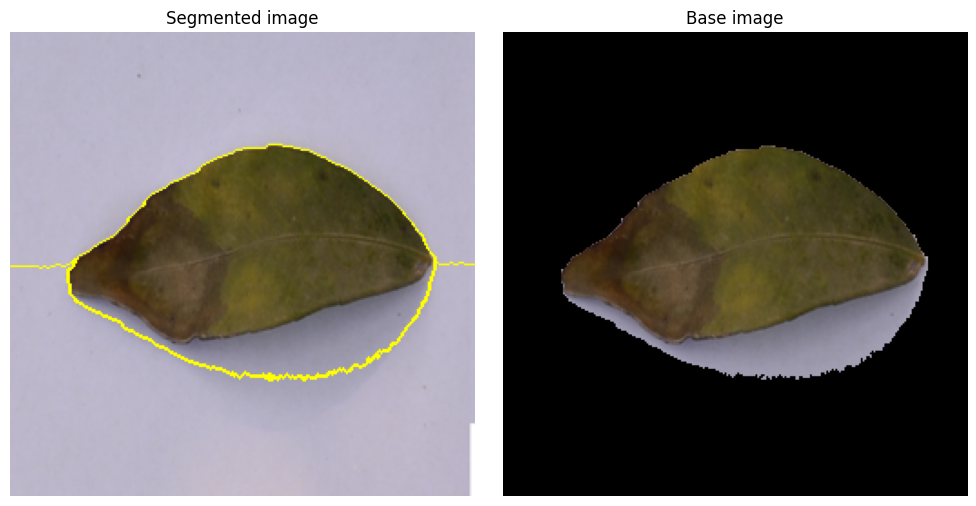

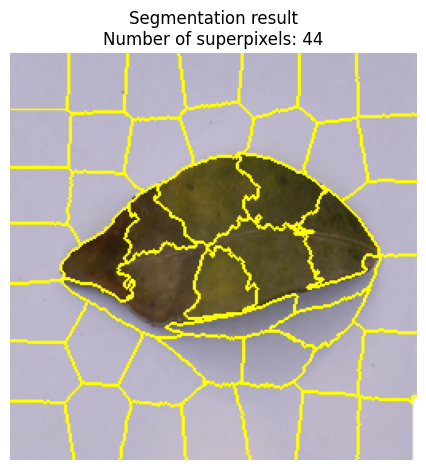

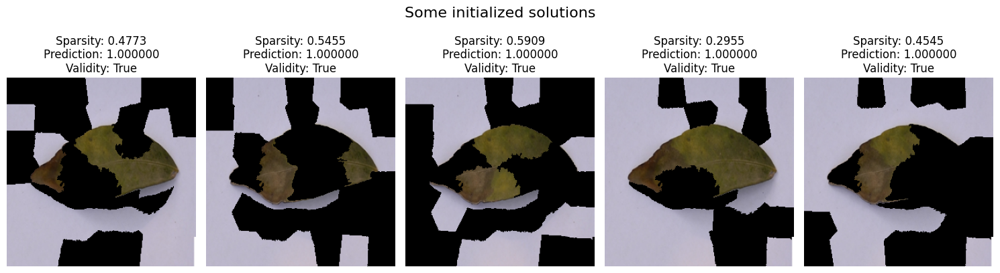

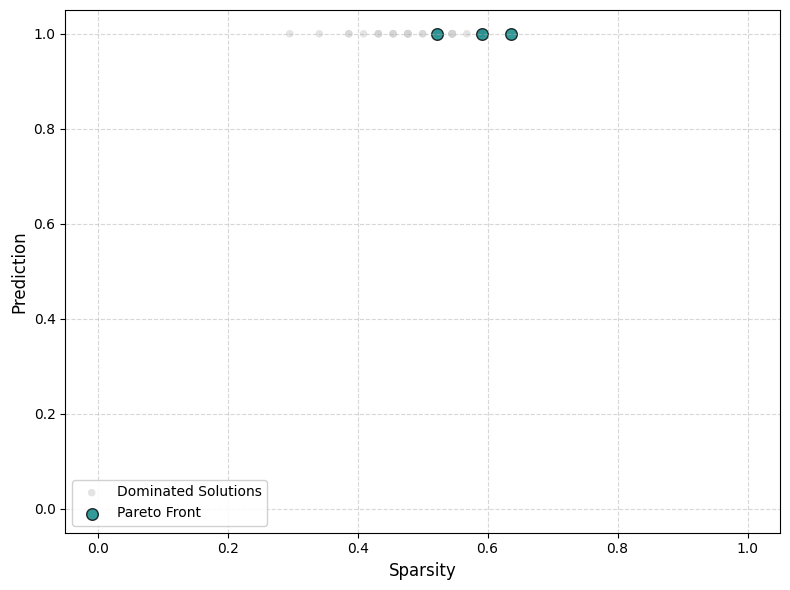

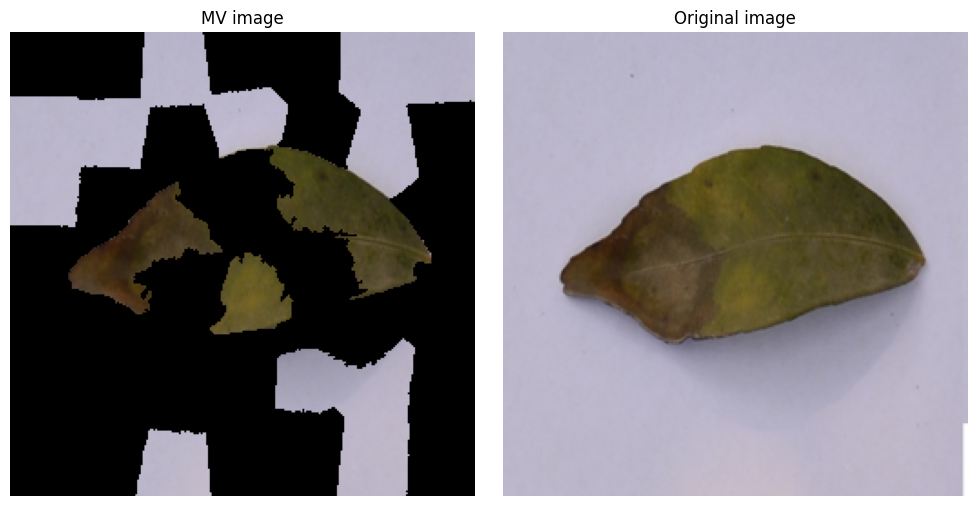


Hypervolume at 1th iteration: 0.7684
Hypervolume at 10th iteration: 1.0306


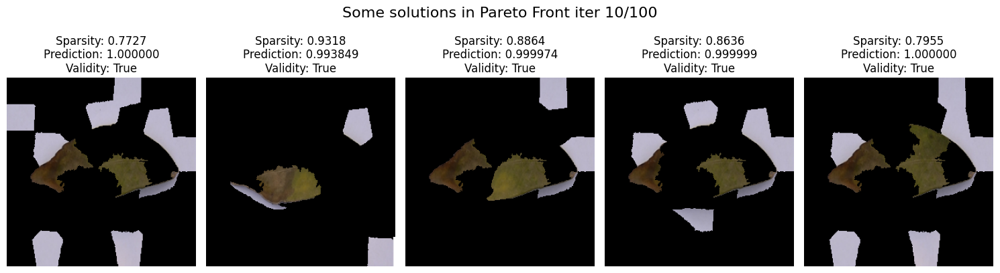

Pareto Front size: 5


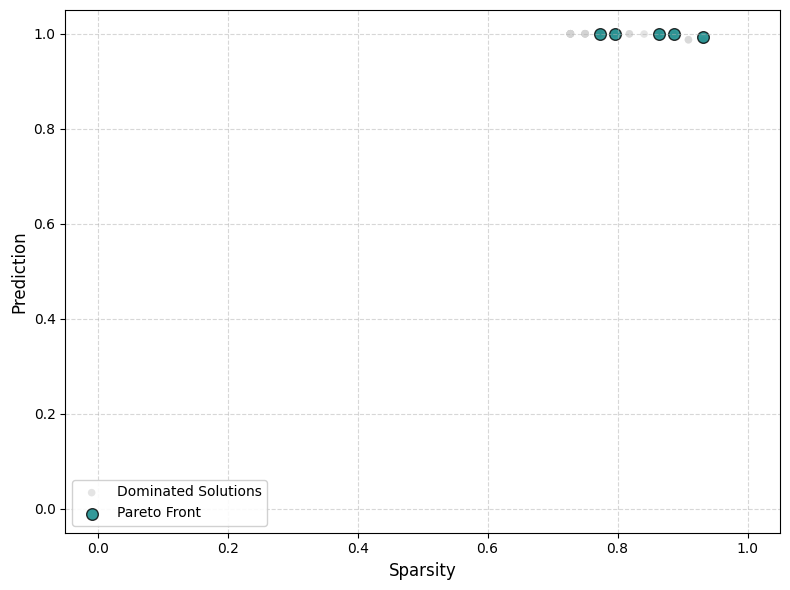

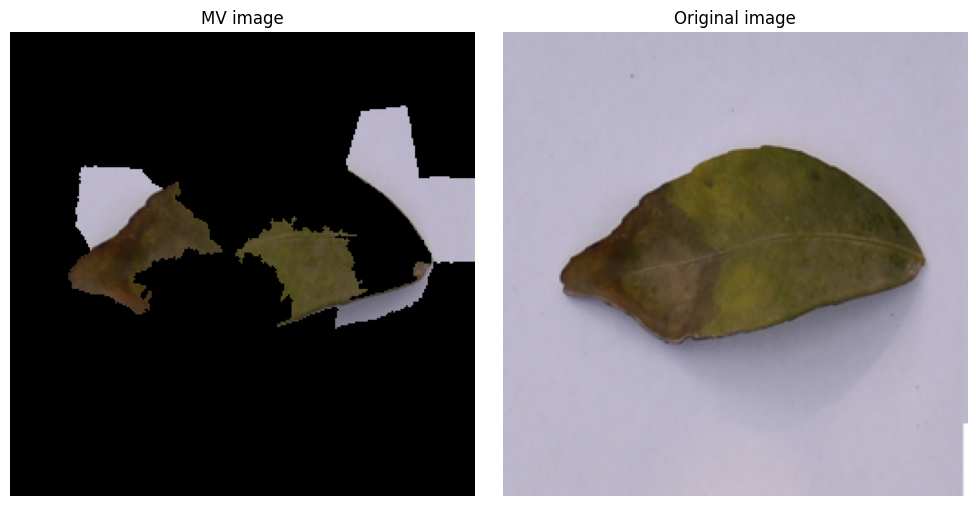


Hypervolume at 20th iteration: 1.0875


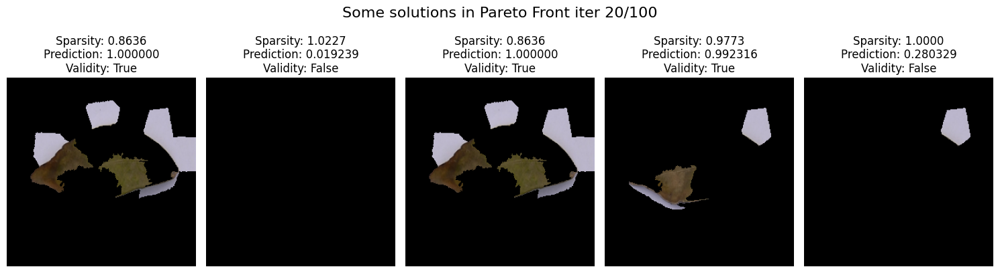

Pareto Front size: 35


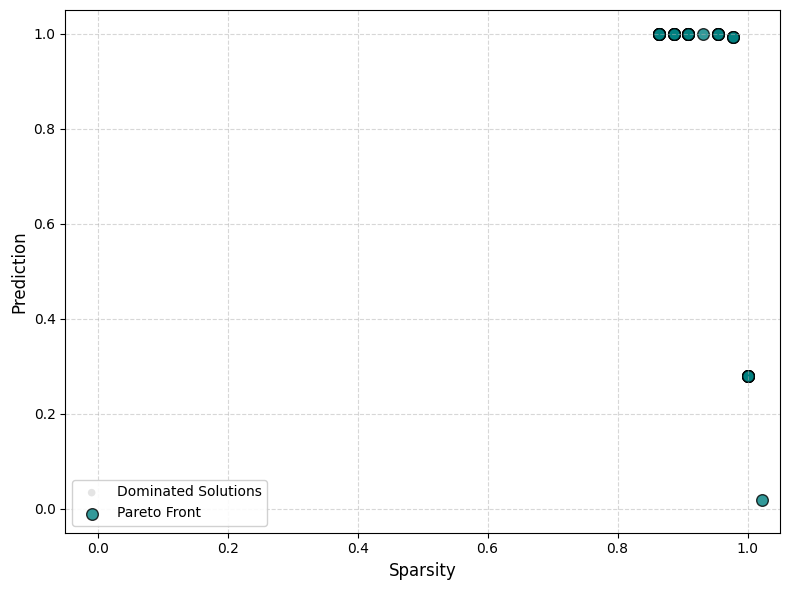

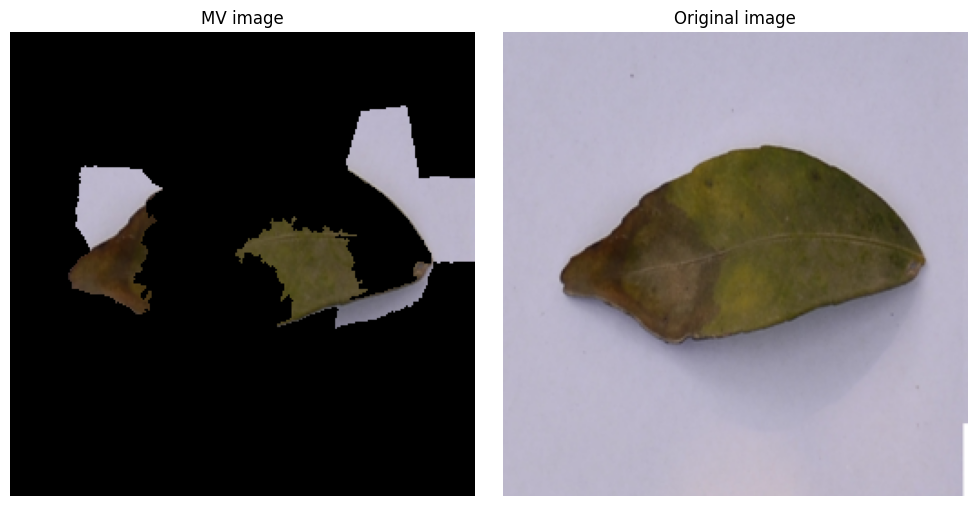


Hypervolume at 30th iteration: 1.1031


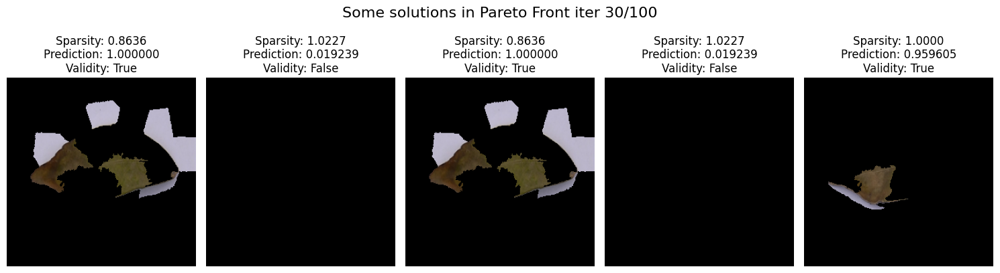

Pareto Front size: 35


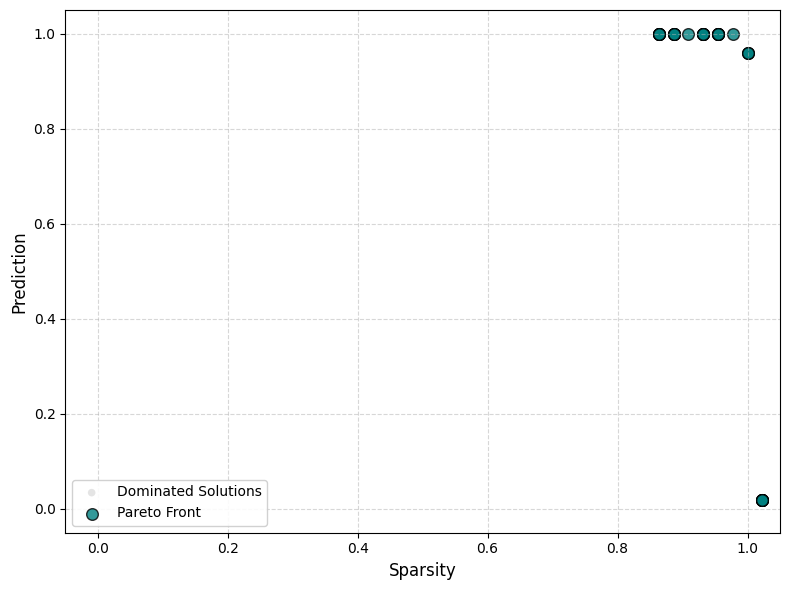

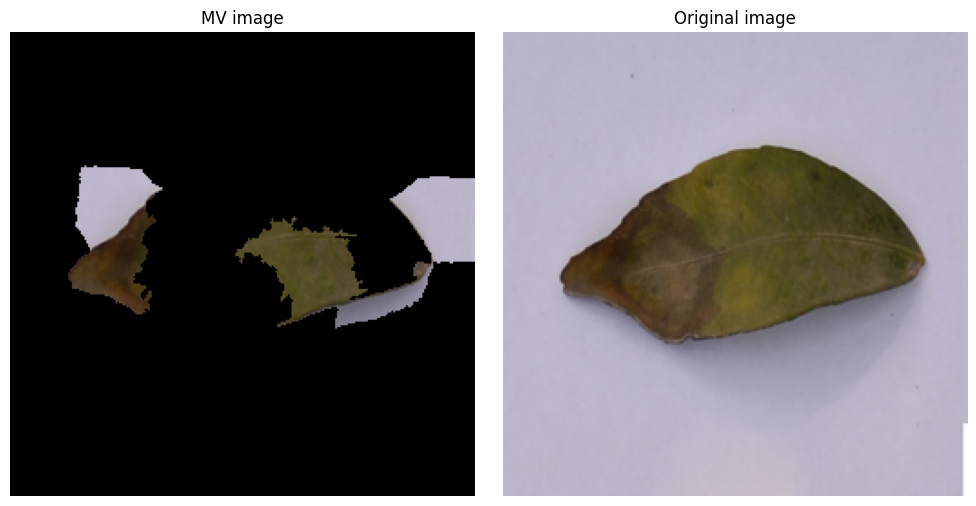


Hypervolume at 40th iteration: 1.1031


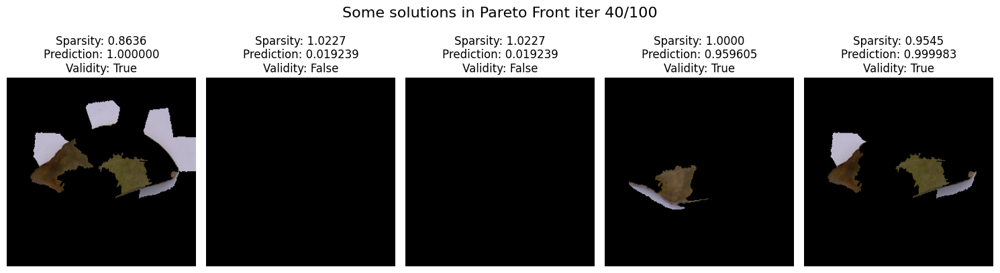

Pareto Front size: 35


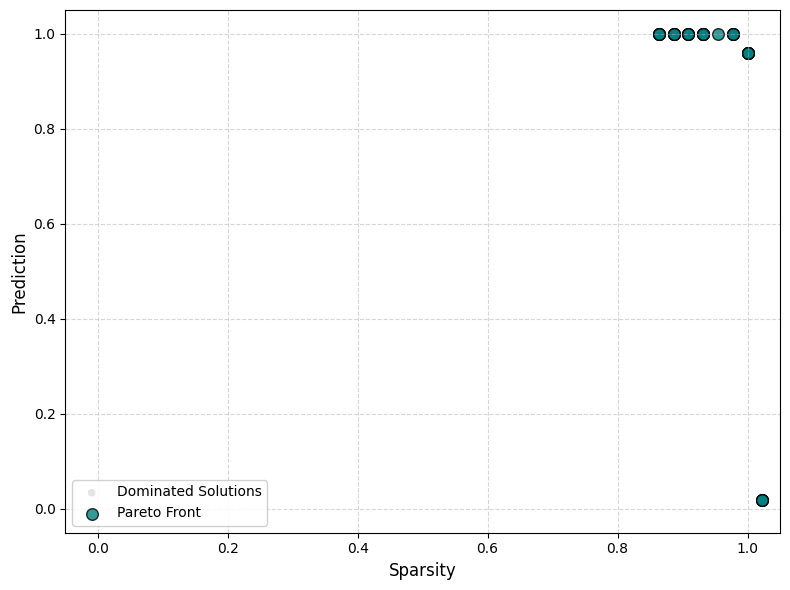

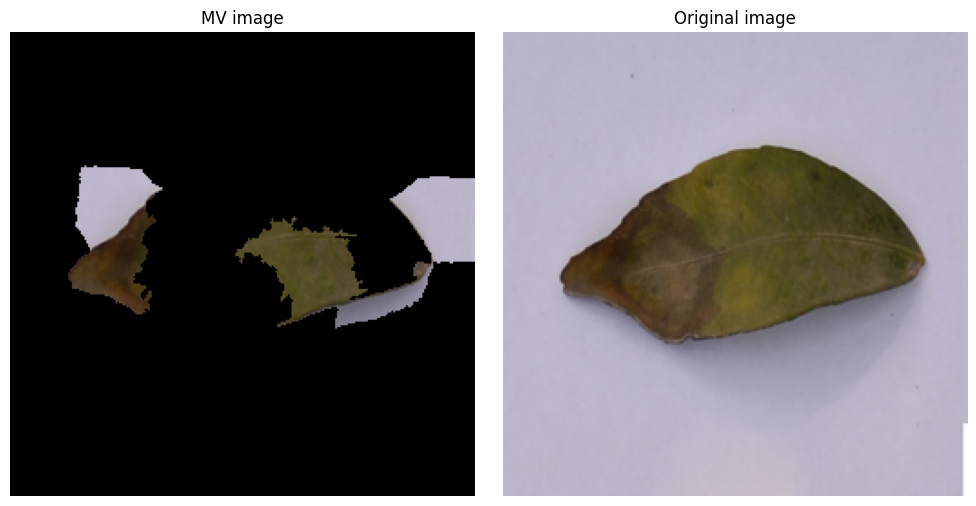


Hypervolume at 50th iteration: 1.1031


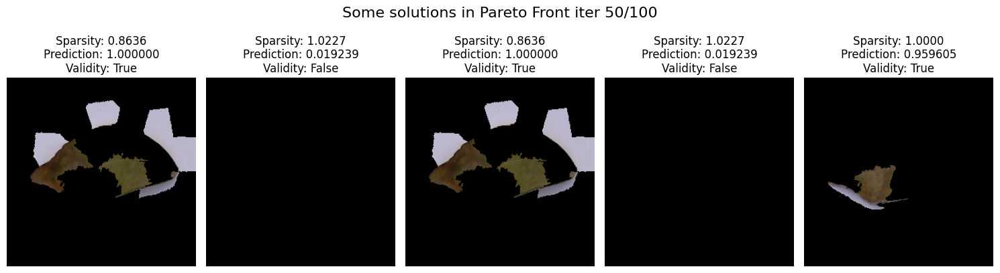

Pareto Front size: 35


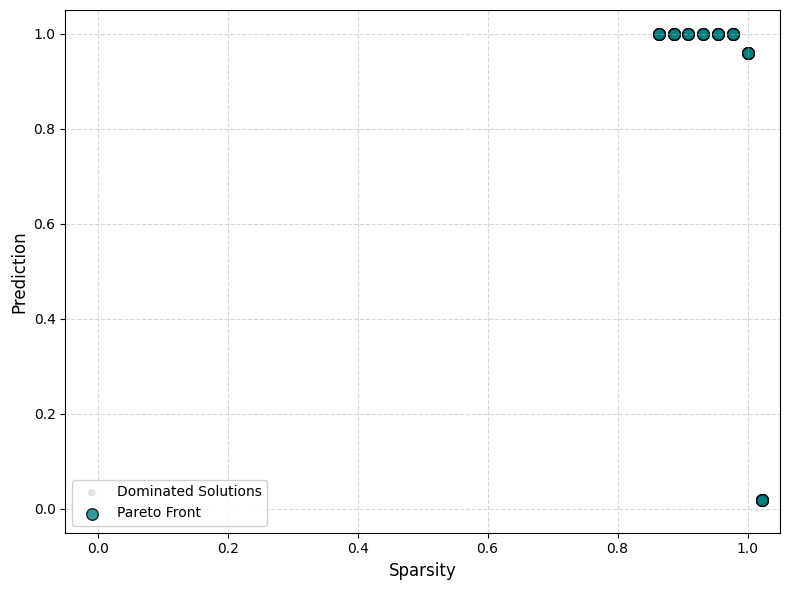

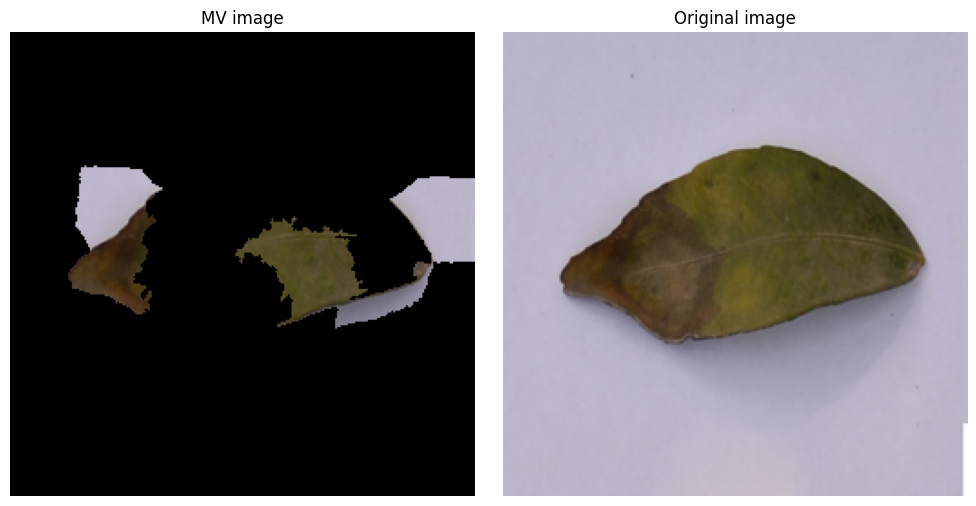


Hypervolume at 60th iteration: 1.1031


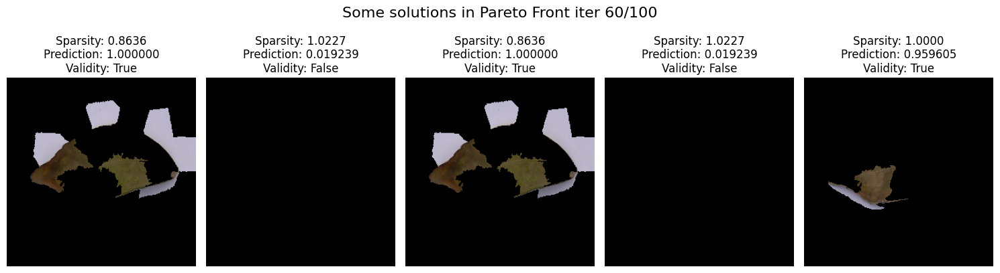

Pareto Front size: 35


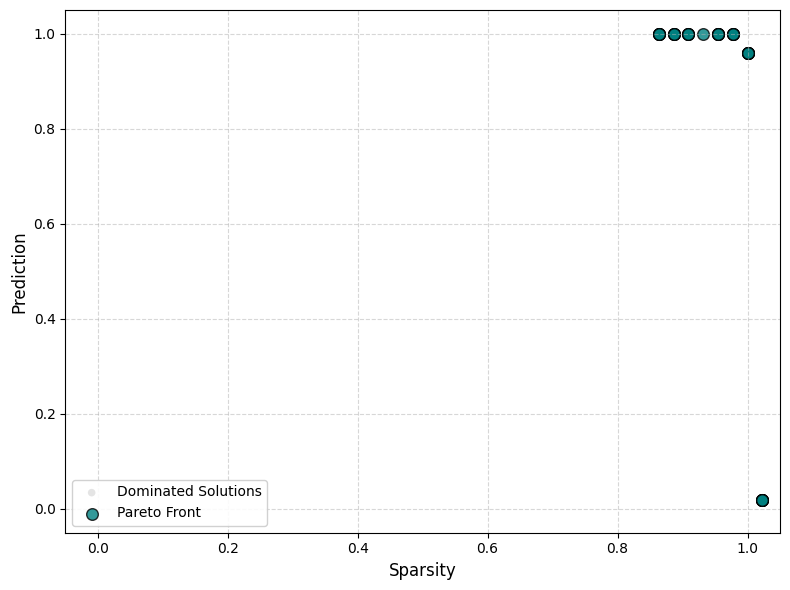

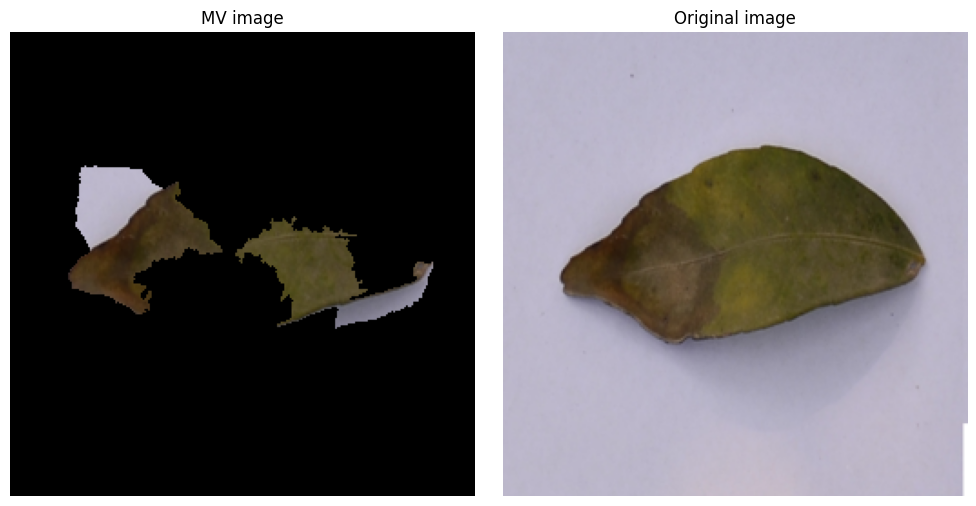


Hypervolume at 70th iteration: 1.1031


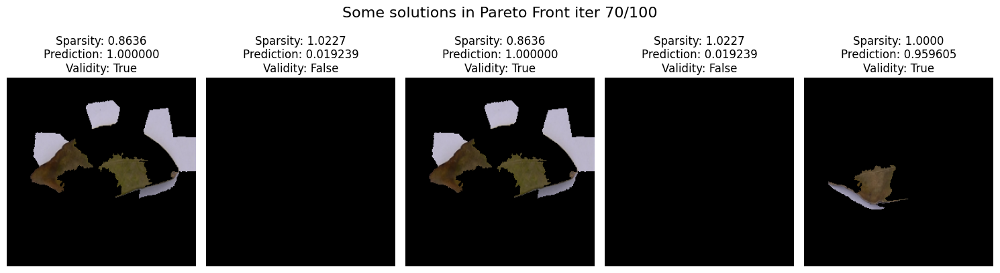

Pareto Front size: 35


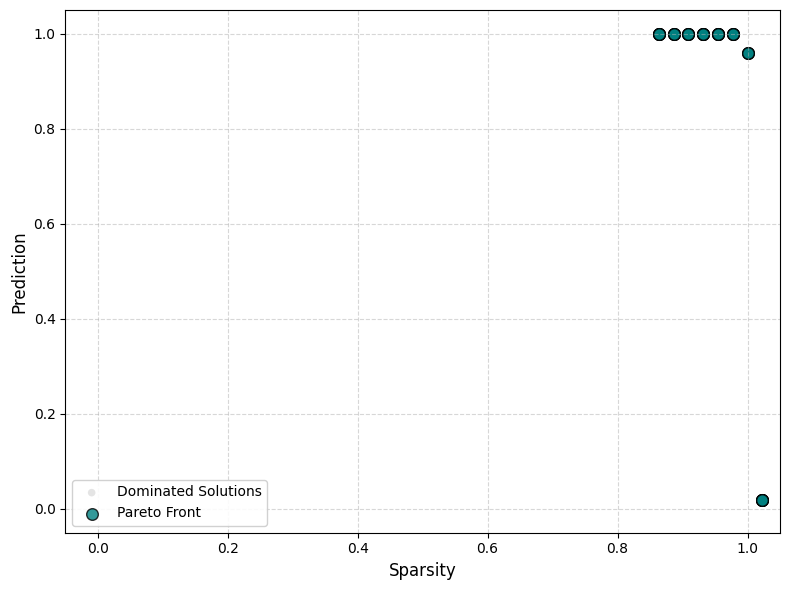

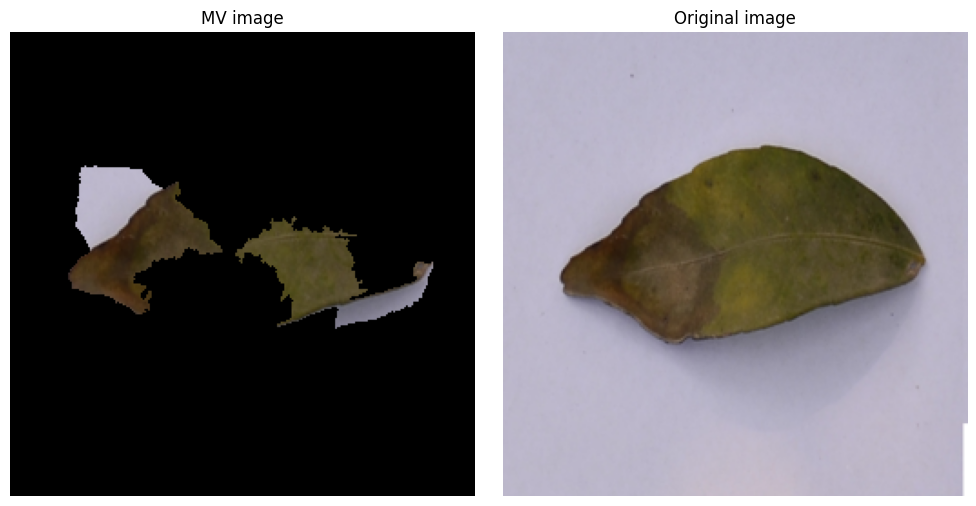


Hypervolume at 80th iteration: 1.1035


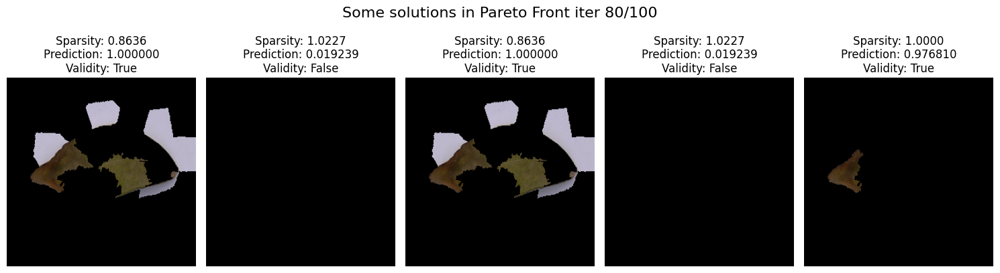

Pareto Front size: 35


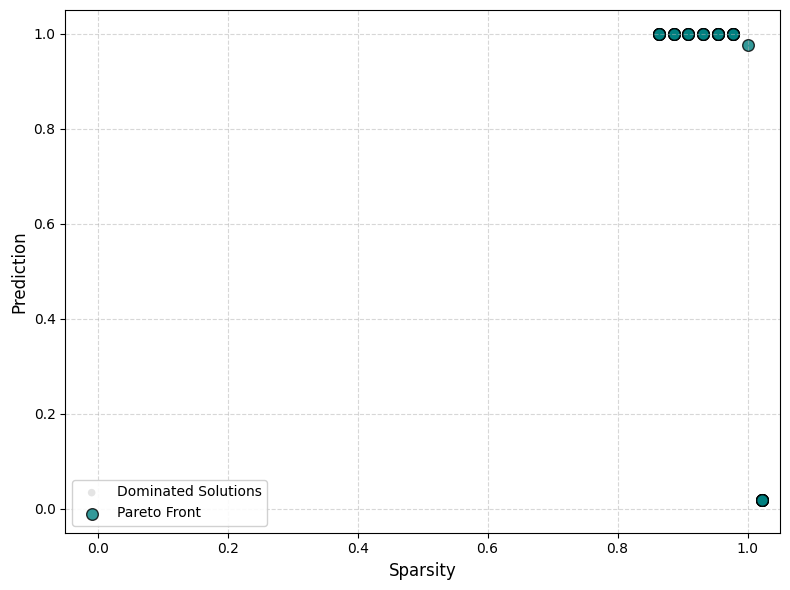

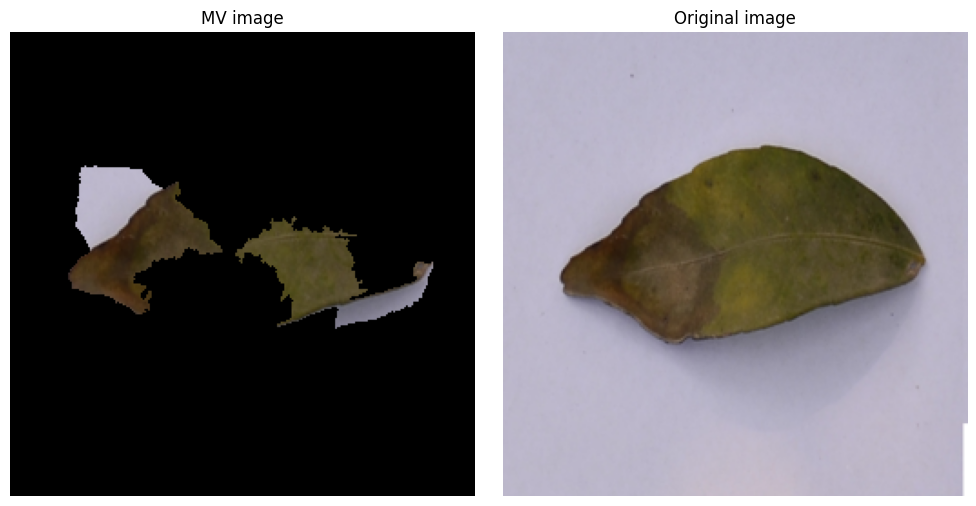


Hypervolume at 90th iteration: 1.1035


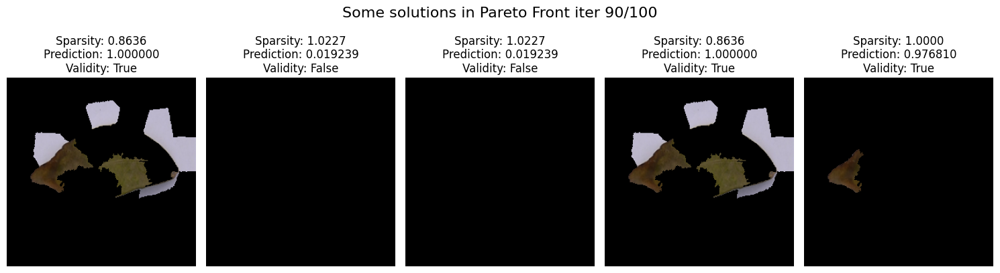

Pareto Front size: 35


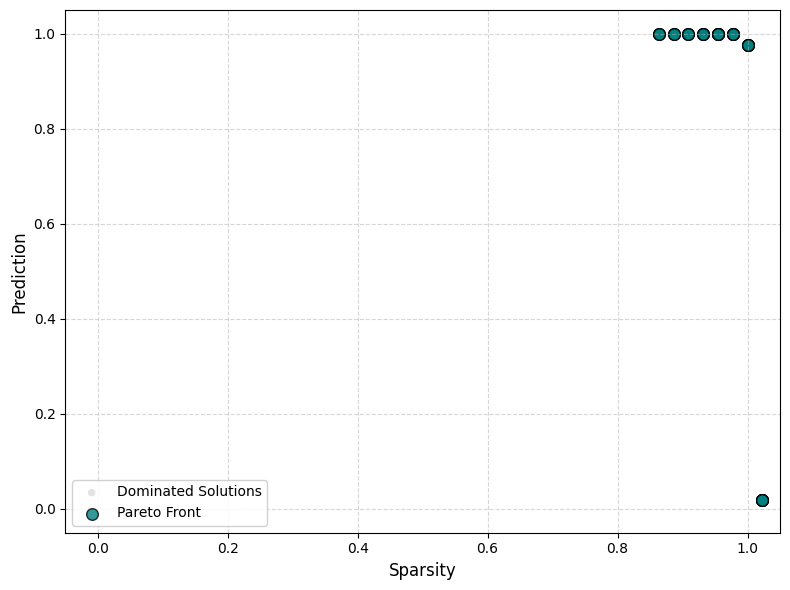

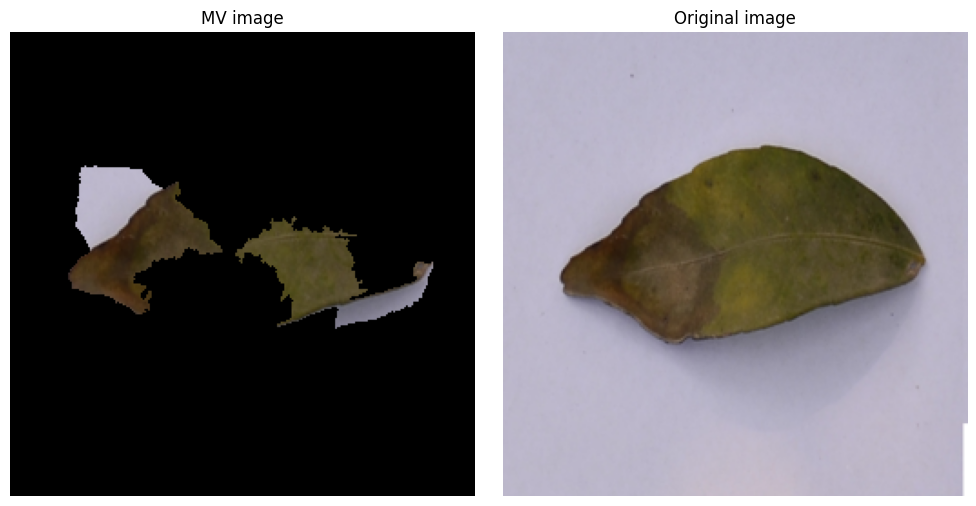


Hypervolume at 100th iteration: 1.1035


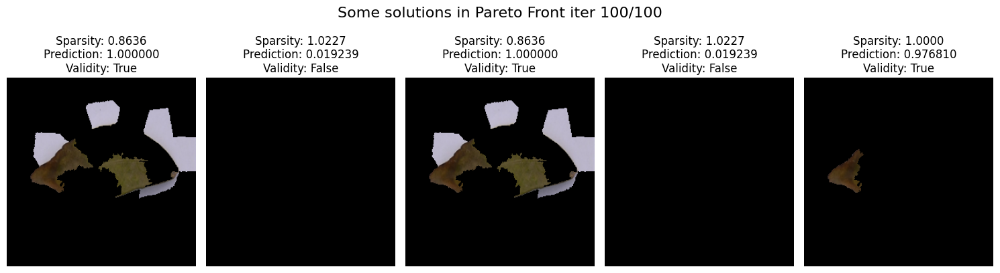

Pareto Front size: 35


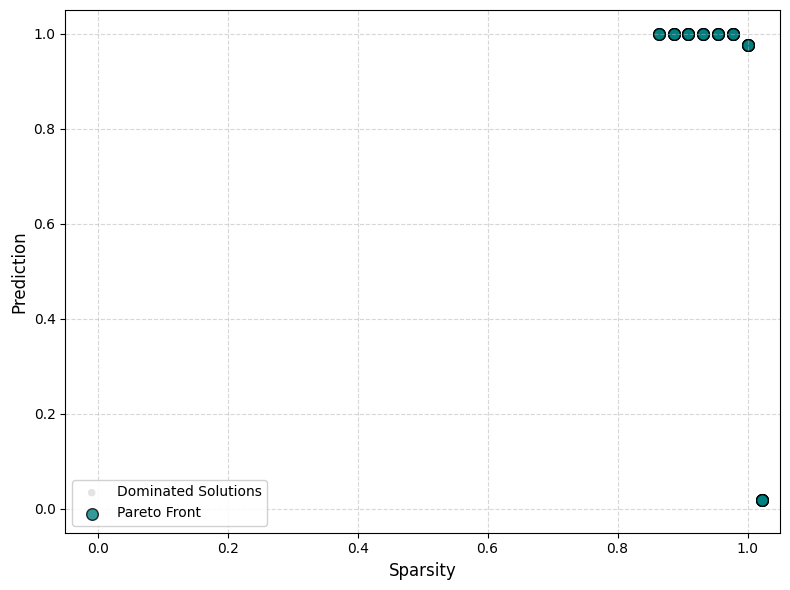

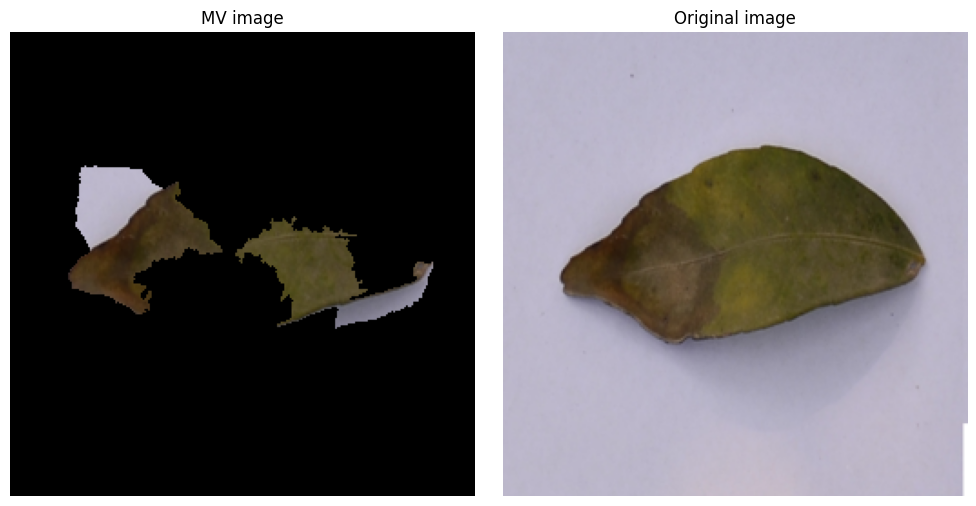

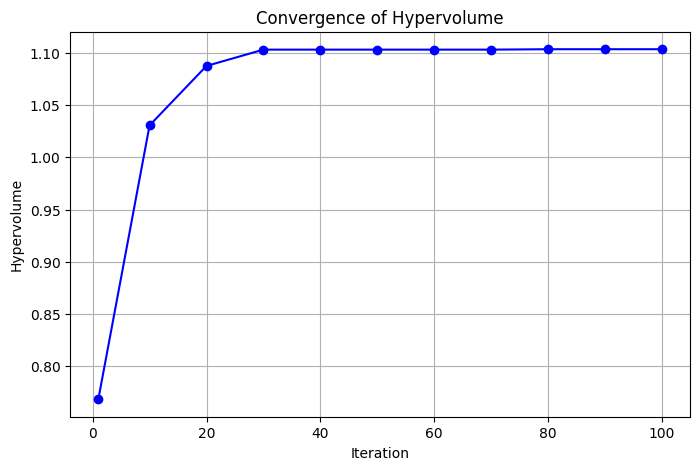

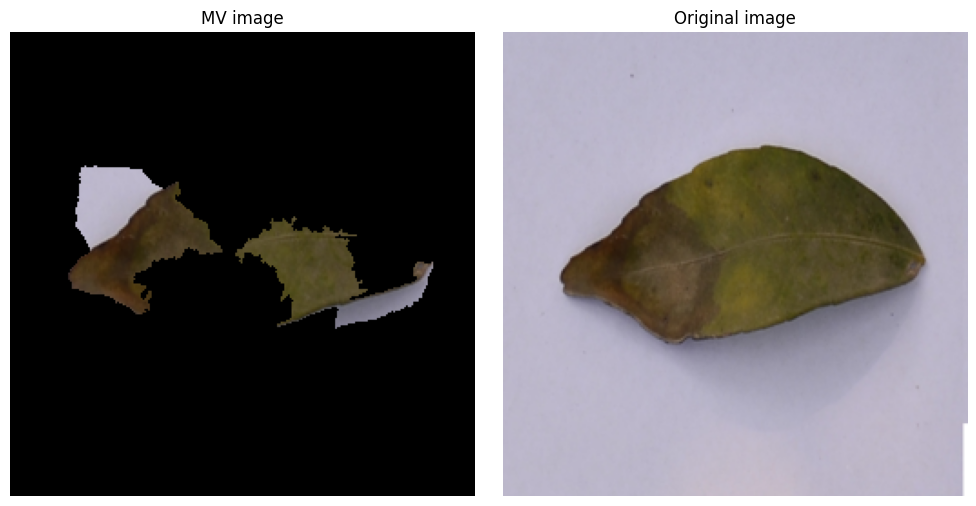

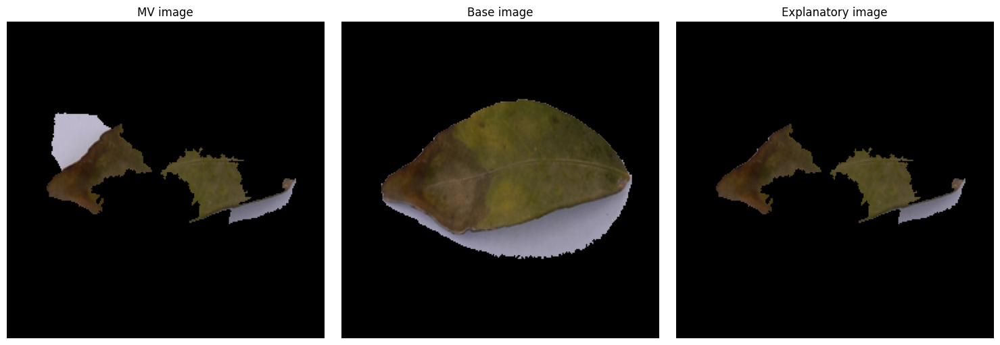

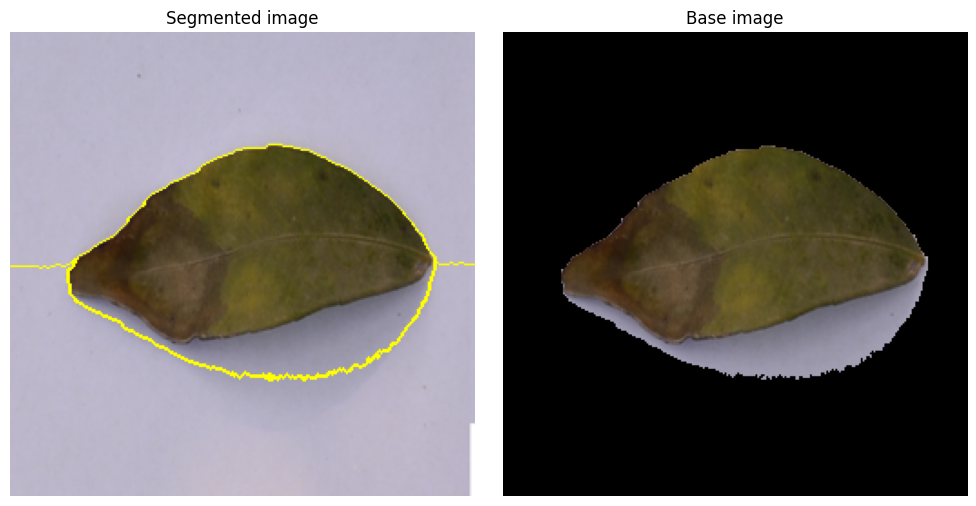

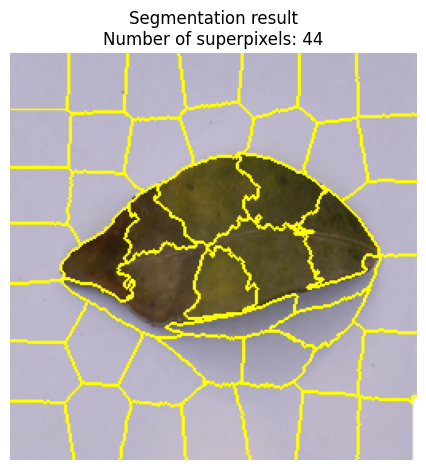

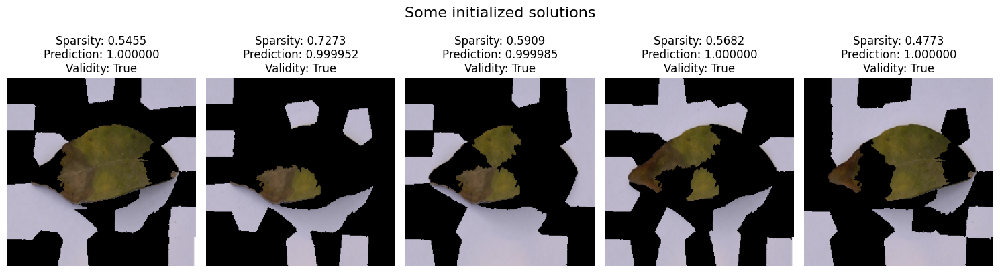

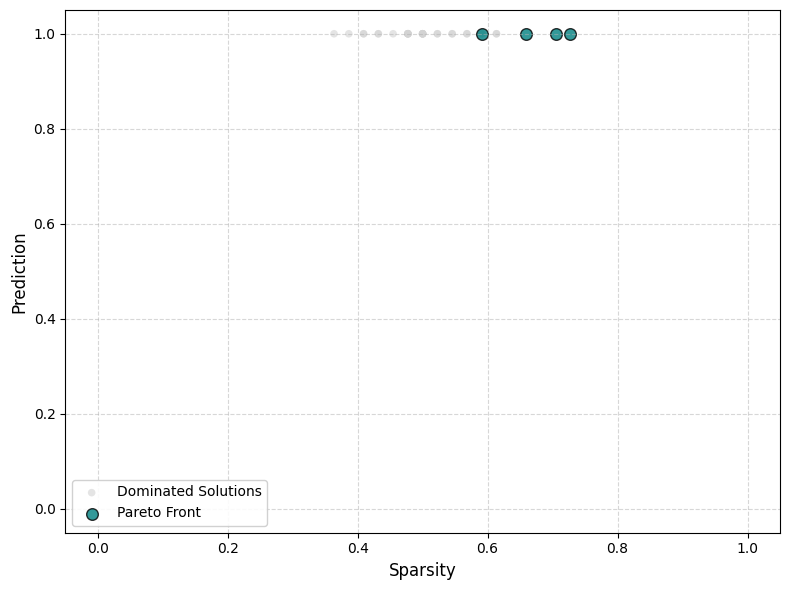

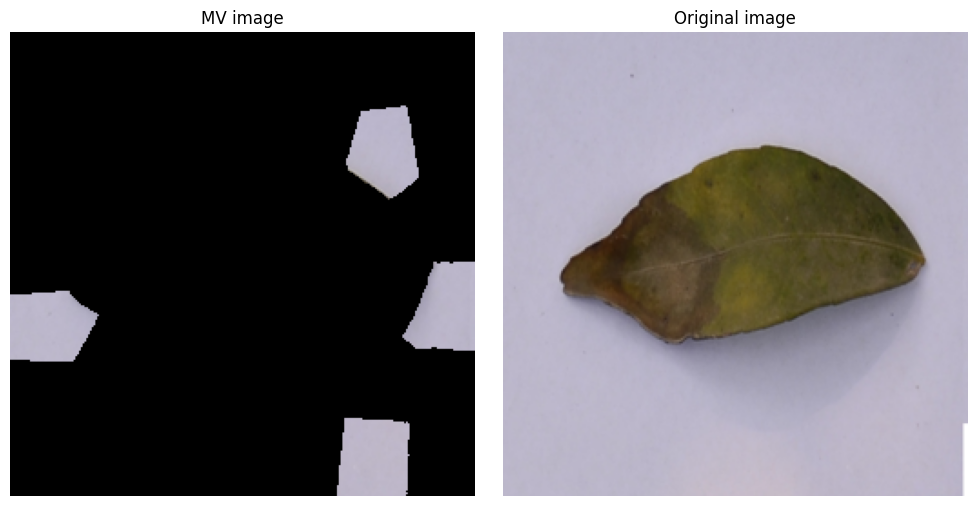


Hypervolume at 1th iteration: 0.8161
Hypervolume at 10th iteration: 1.0309


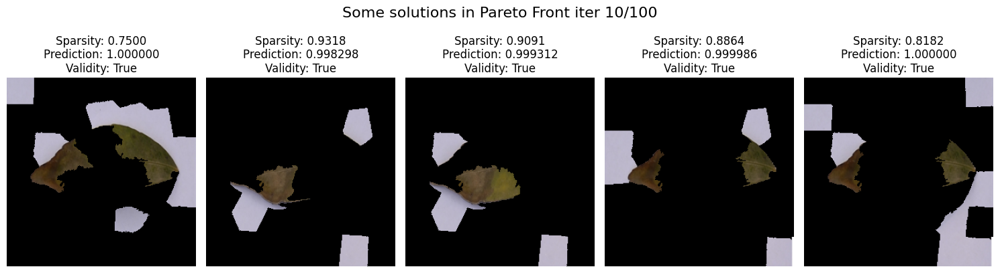

Pareto Front size: 7


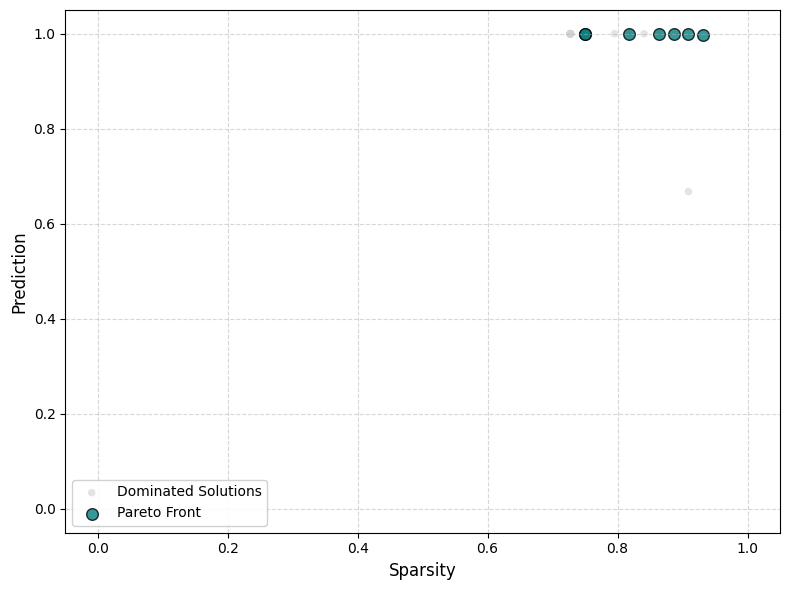

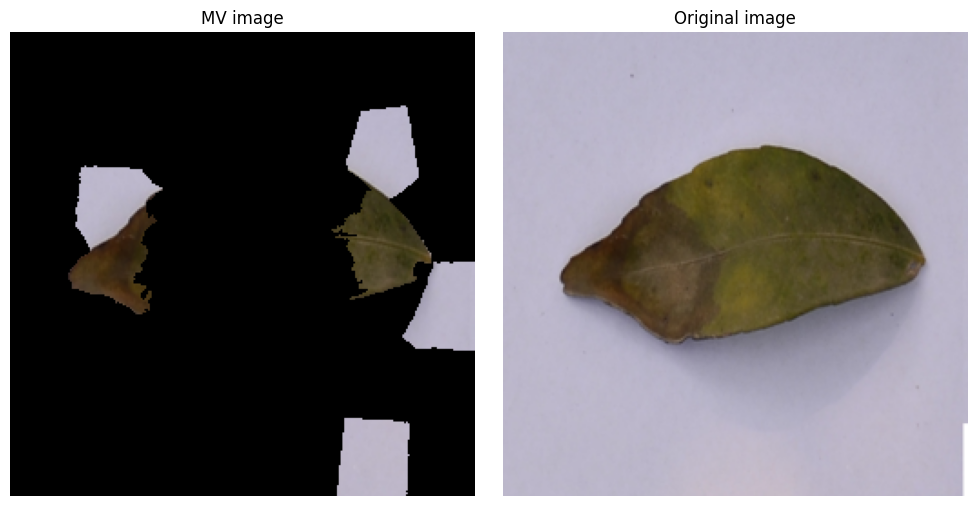


Hypervolume at 20th iteration: 1.1031


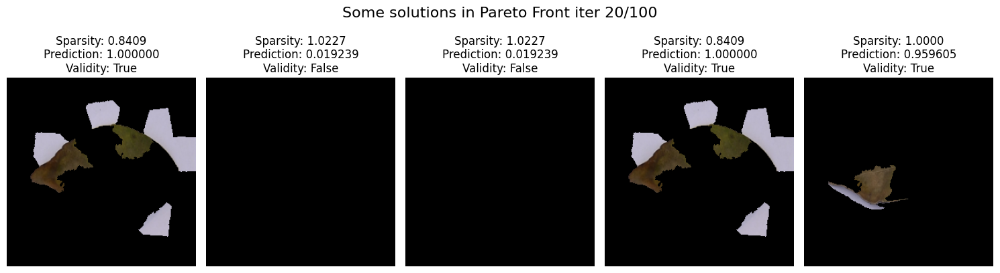

Pareto Front size: 35


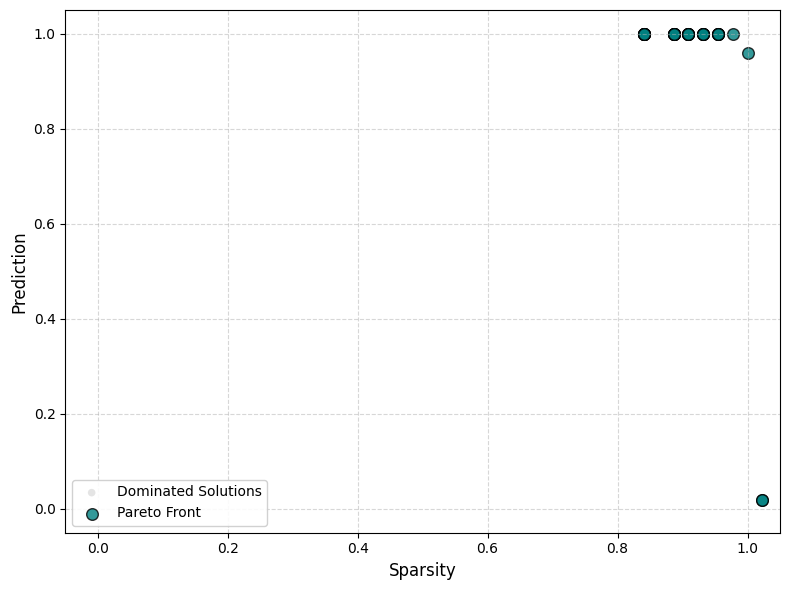

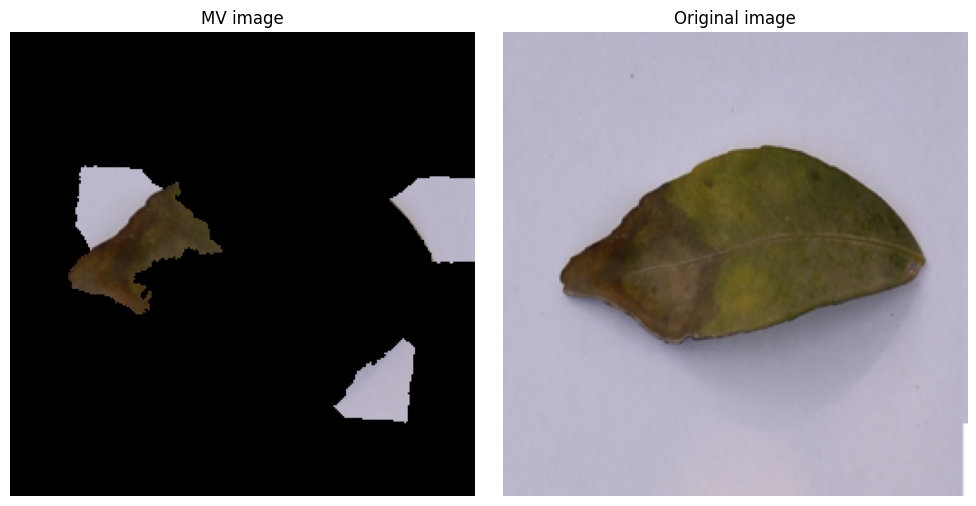


Hypervolume at 30th iteration: 1.1035


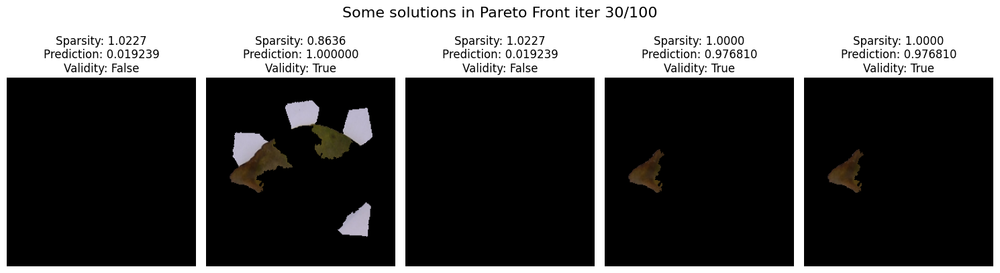

Pareto Front size: 35


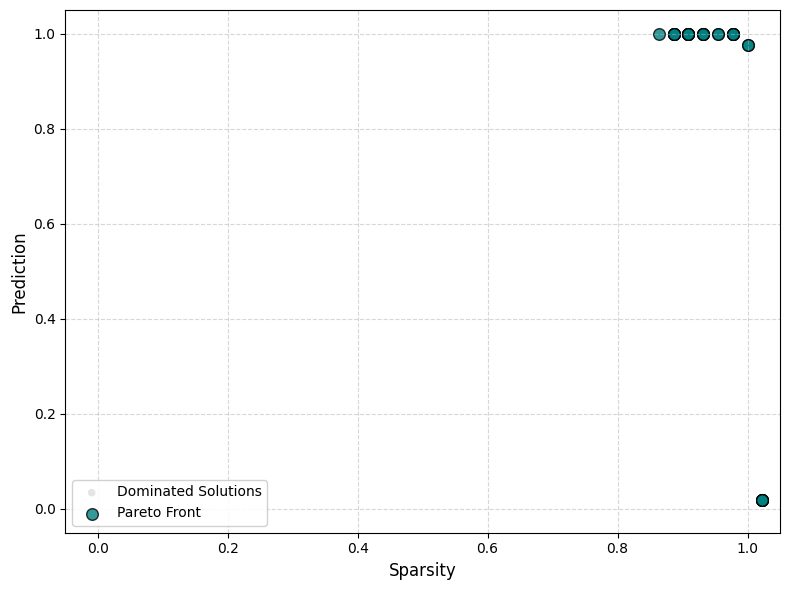

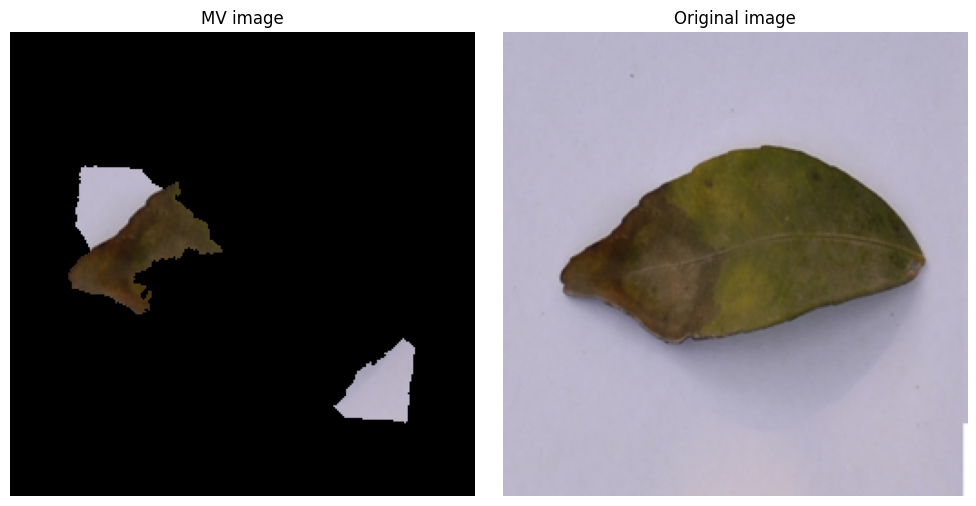


Hypervolume at 40th iteration: 1.1035


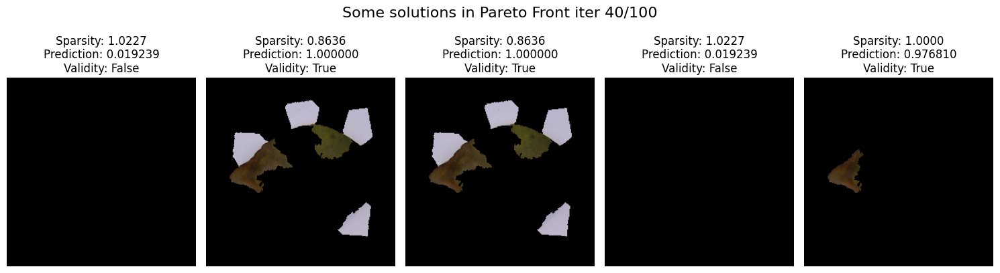

Pareto Front size: 35


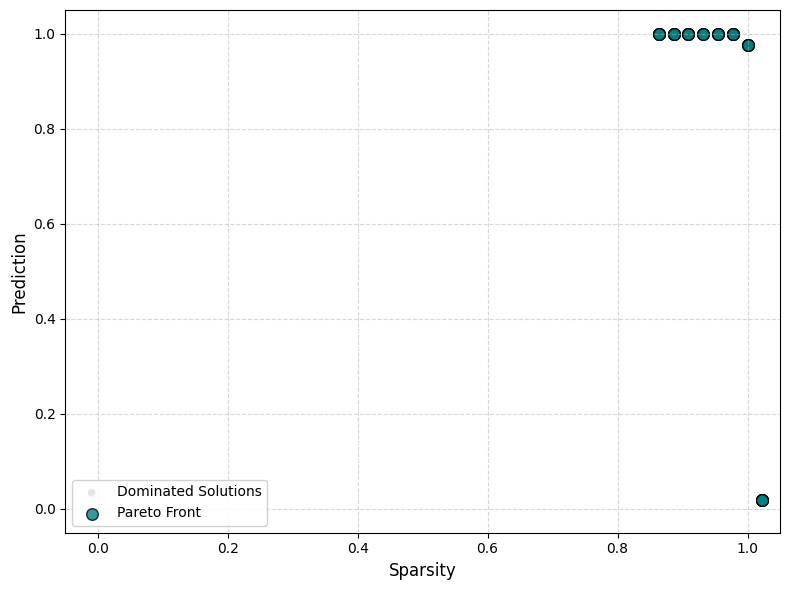

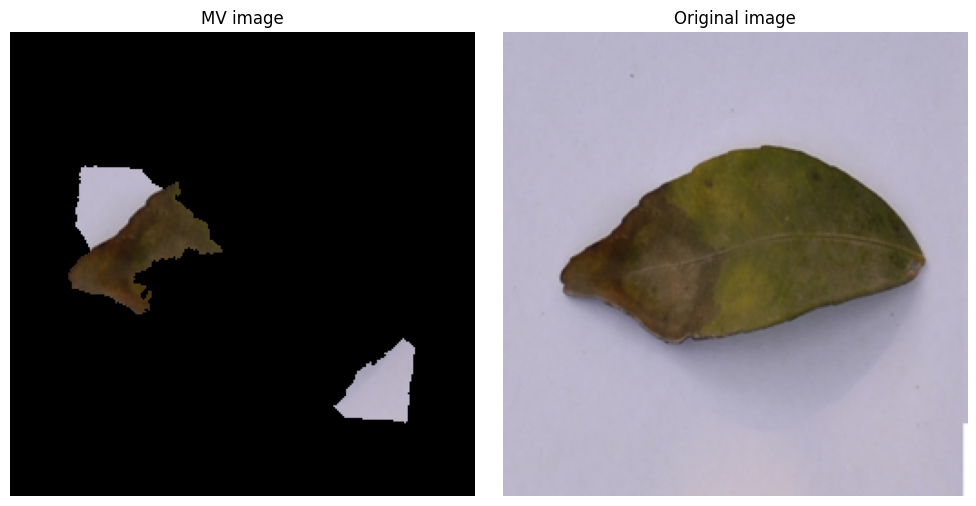


Hypervolume at 50th iteration: 1.1035


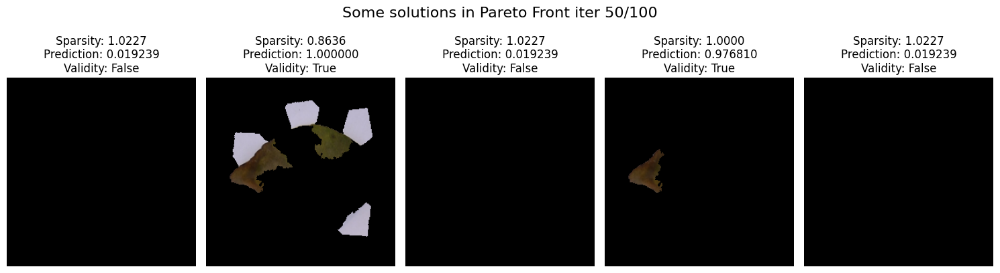

Pareto Front size: 35


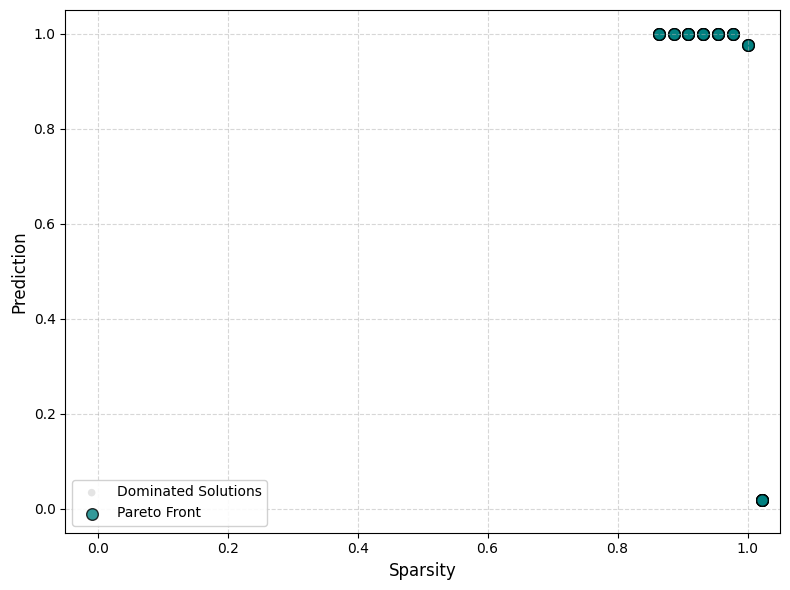

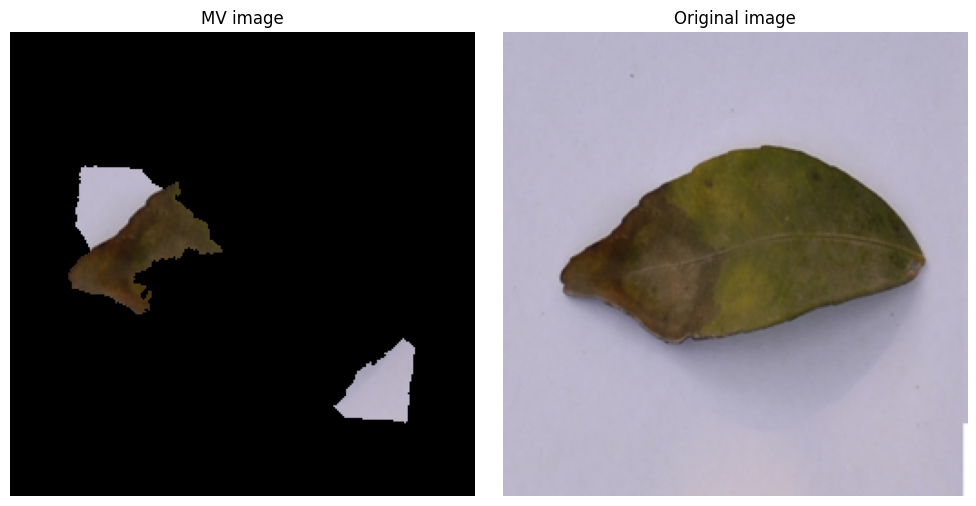


Hypervolume at 60th iteration: 1.1035


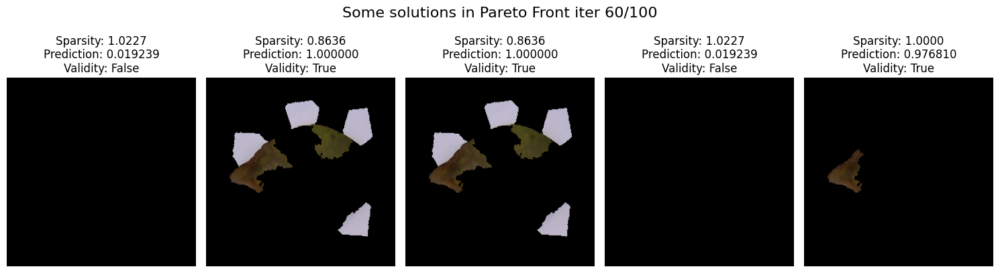

Pareto Front size: 35


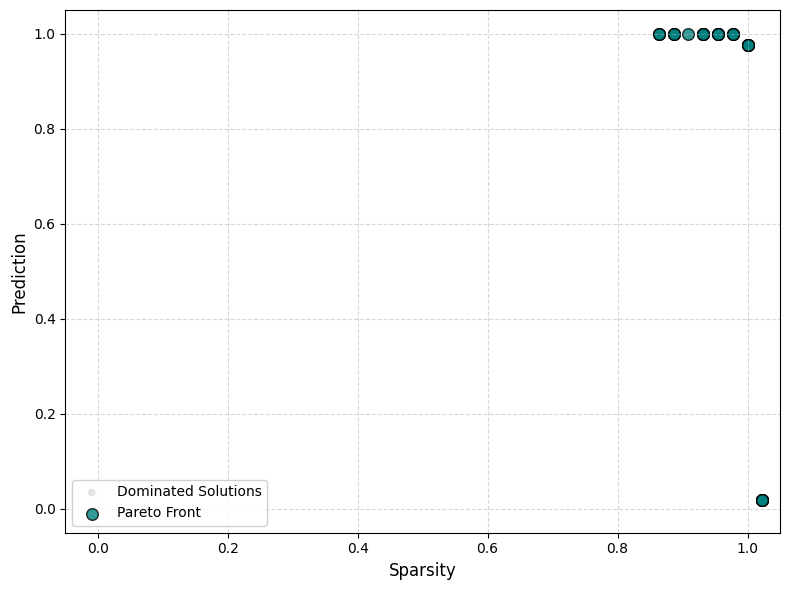

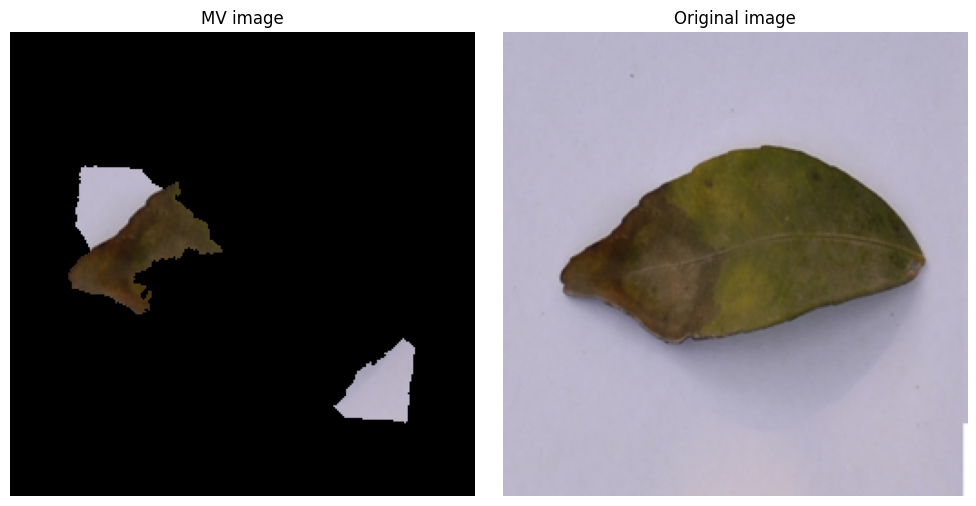


Hypervolume at 70th iteration: 1.1035


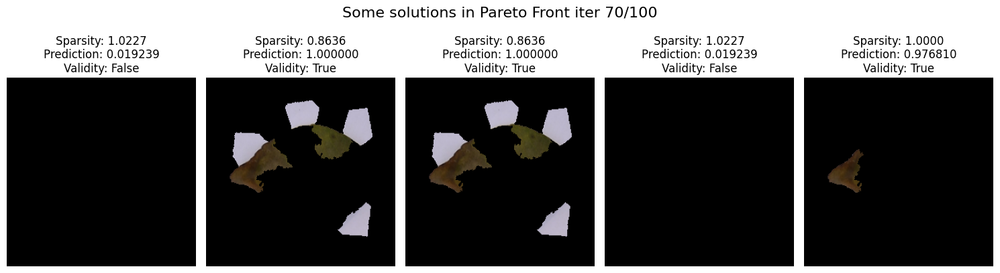

Pareto Front size: 35


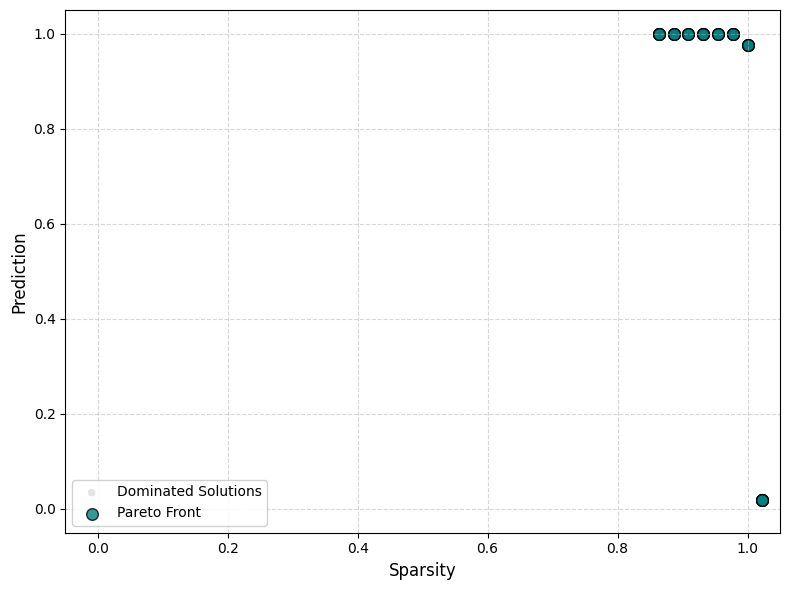

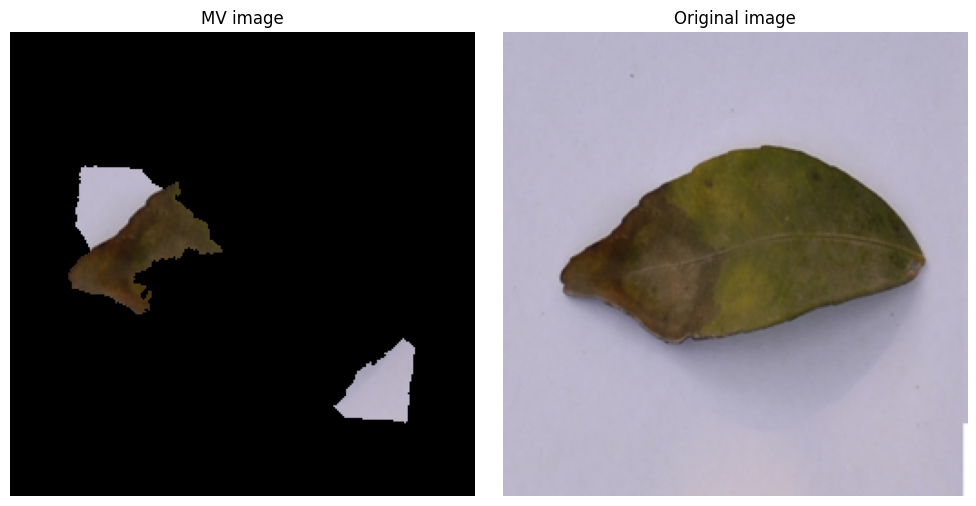


Hypervolume at 80th iteration: 1.1035


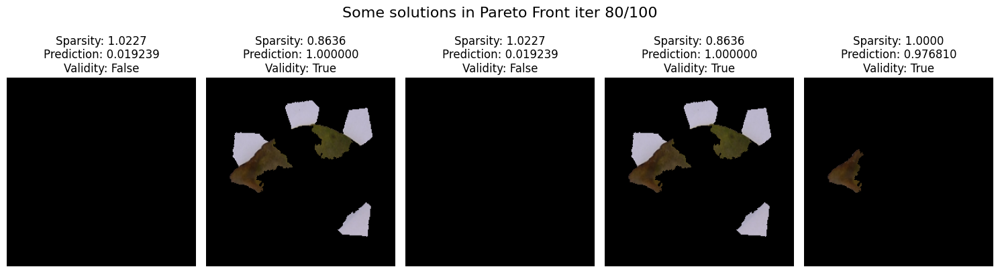

Pareto Front size: 35


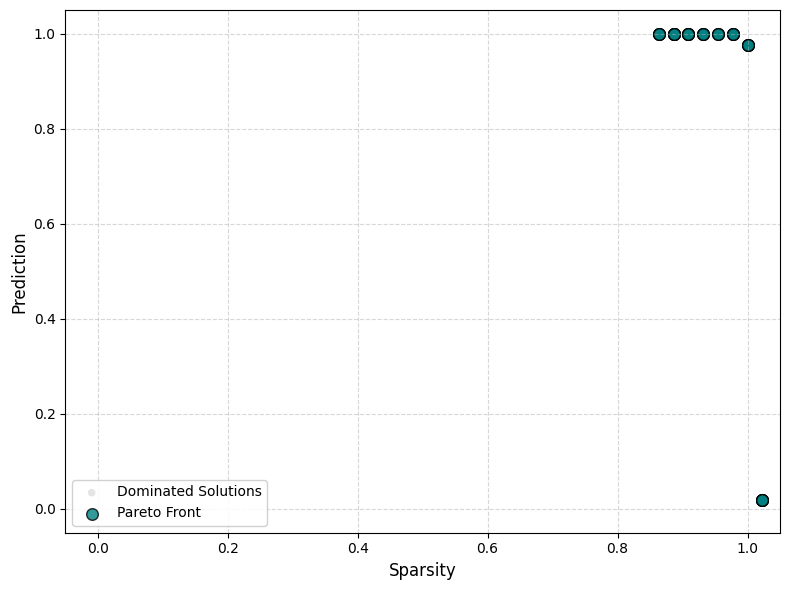

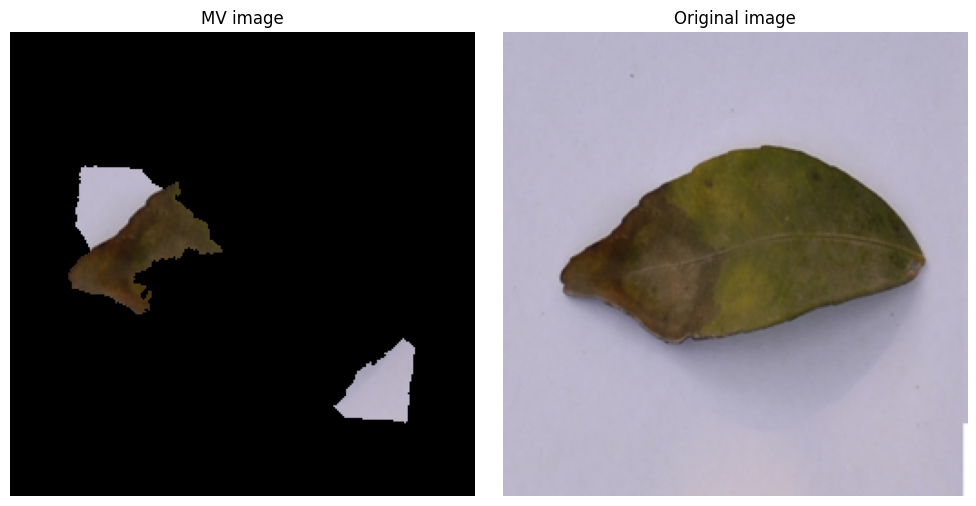


Hypervolume at 90th iteration: 1.1035


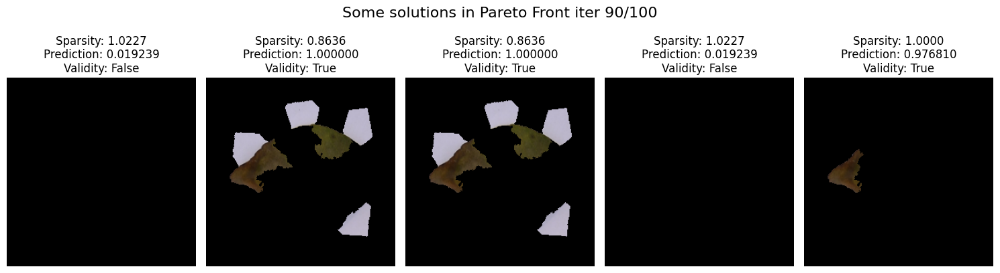

Pareto Front size: 35


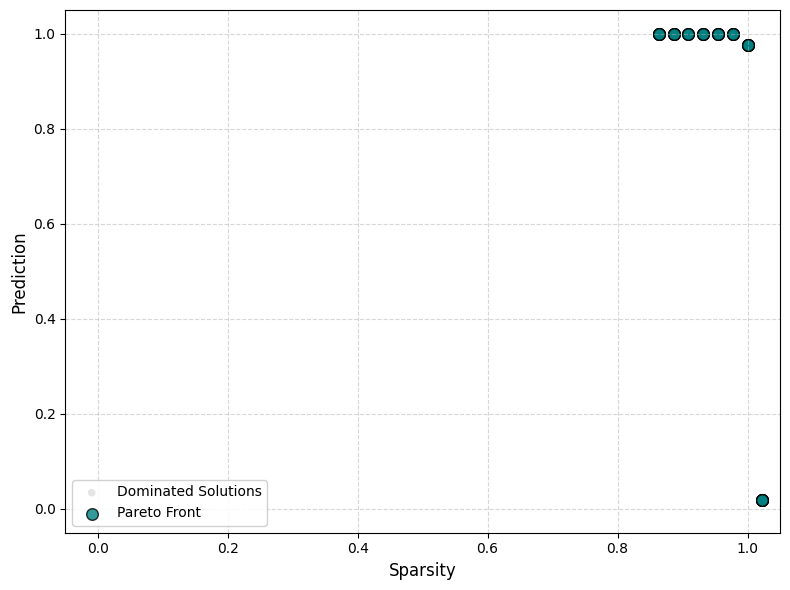

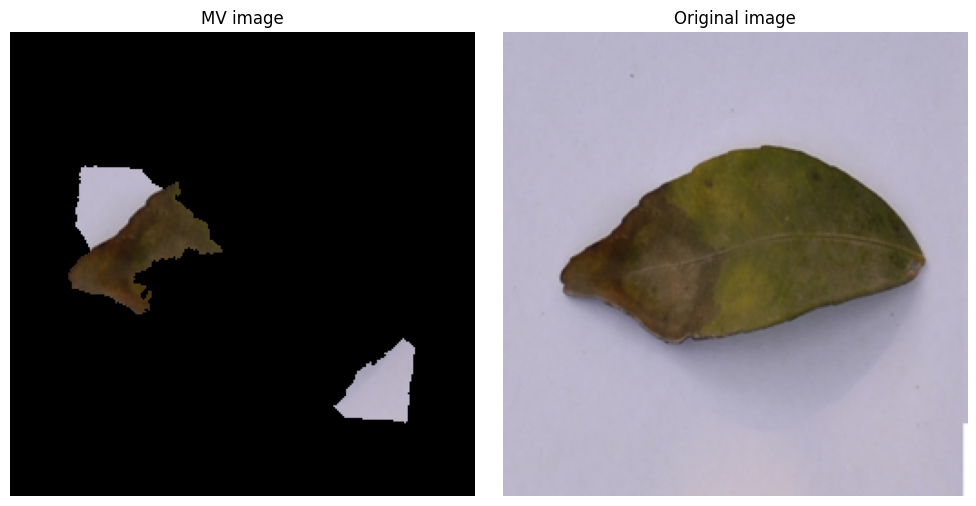


Hypervolume at 100th iteration: 1.1035


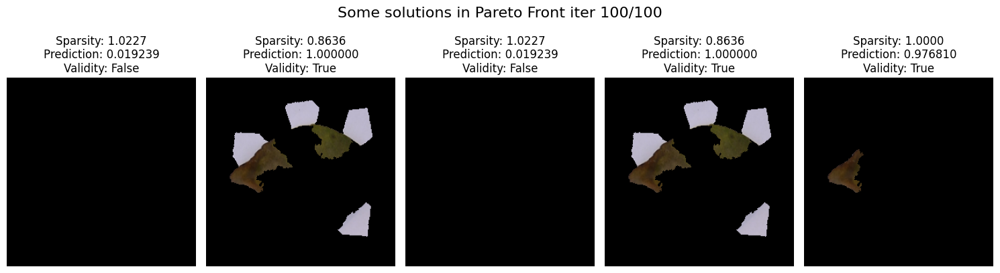

Pareto Front size: 35


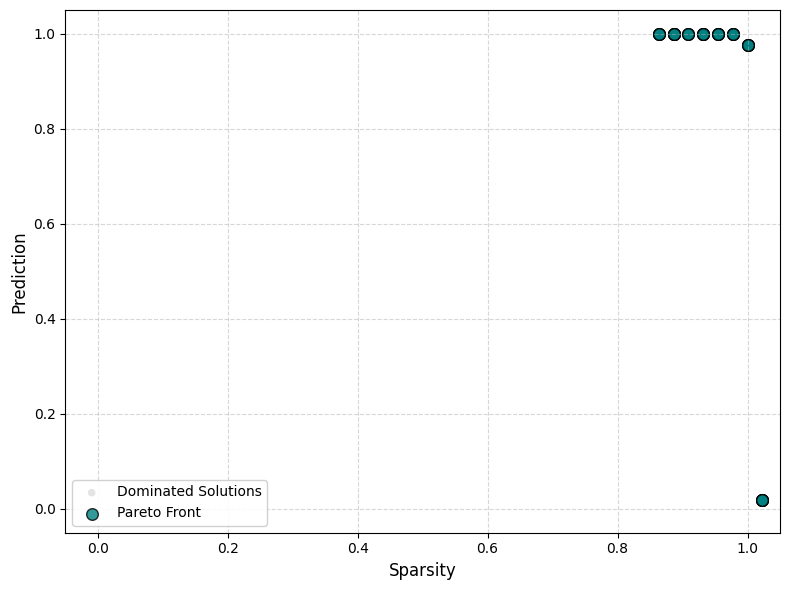

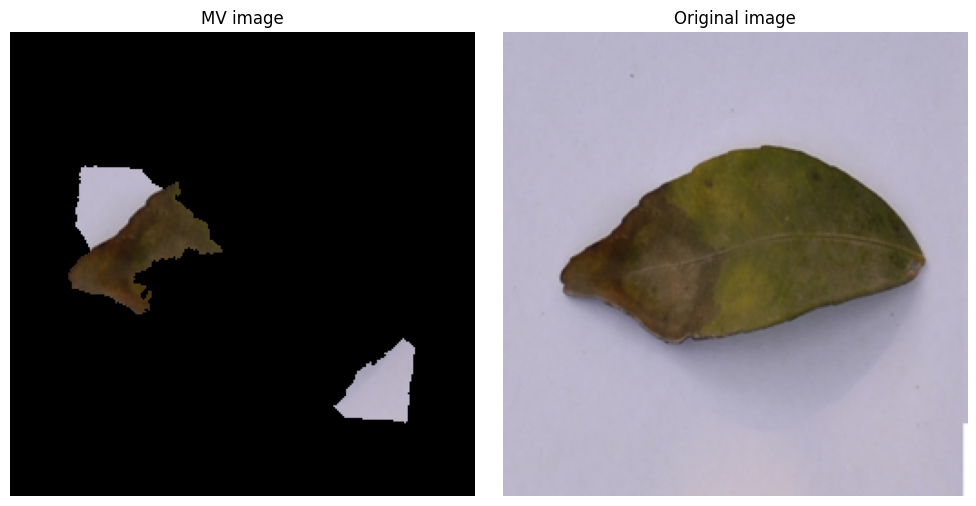

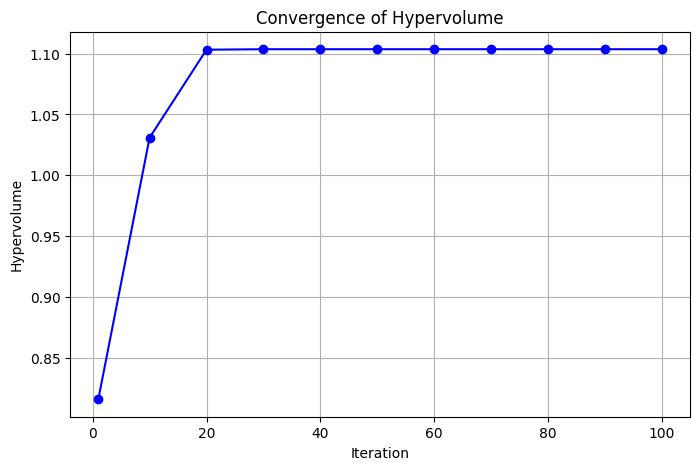

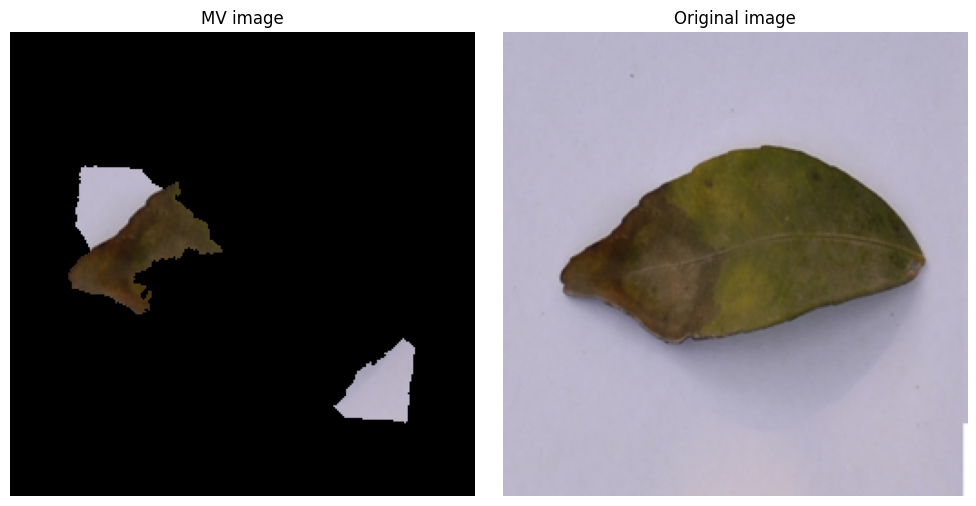

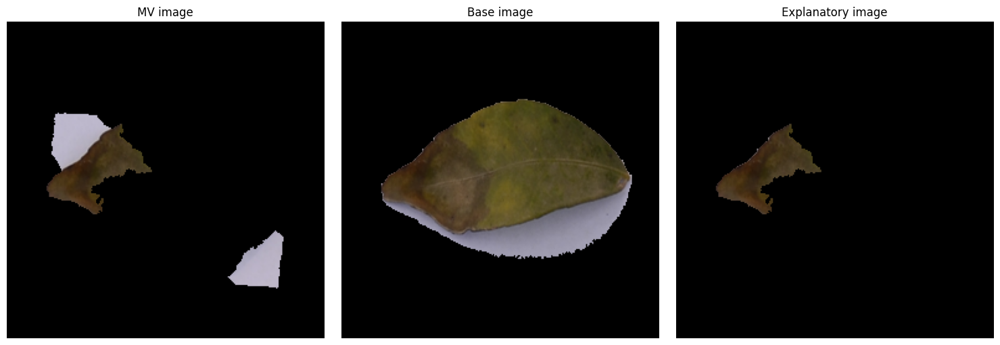

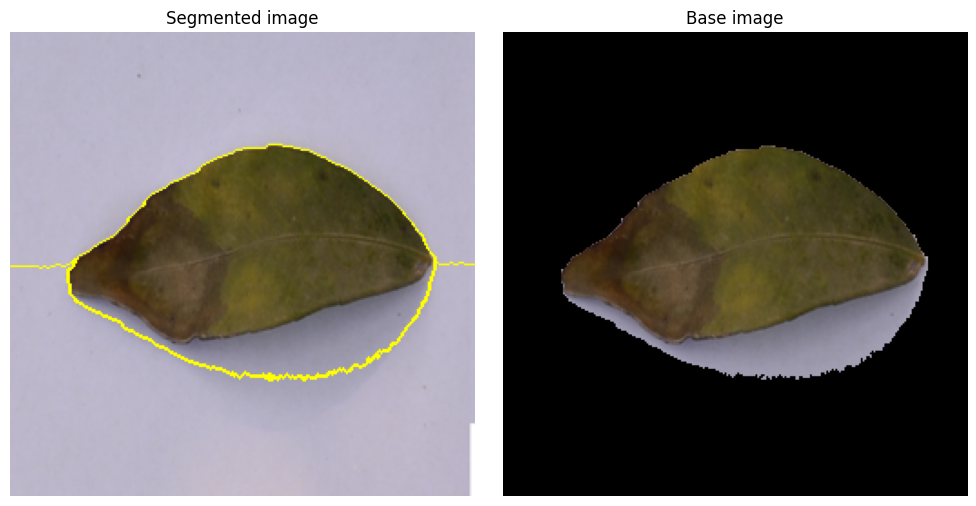

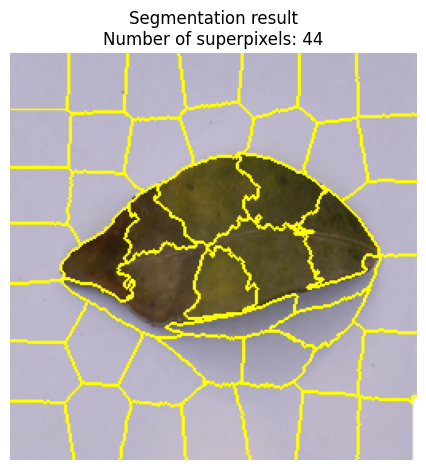

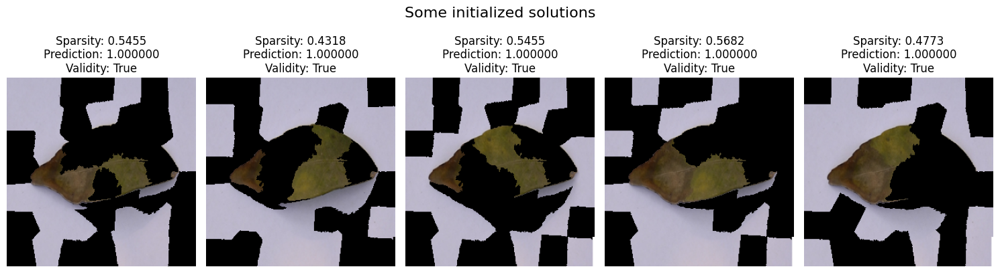

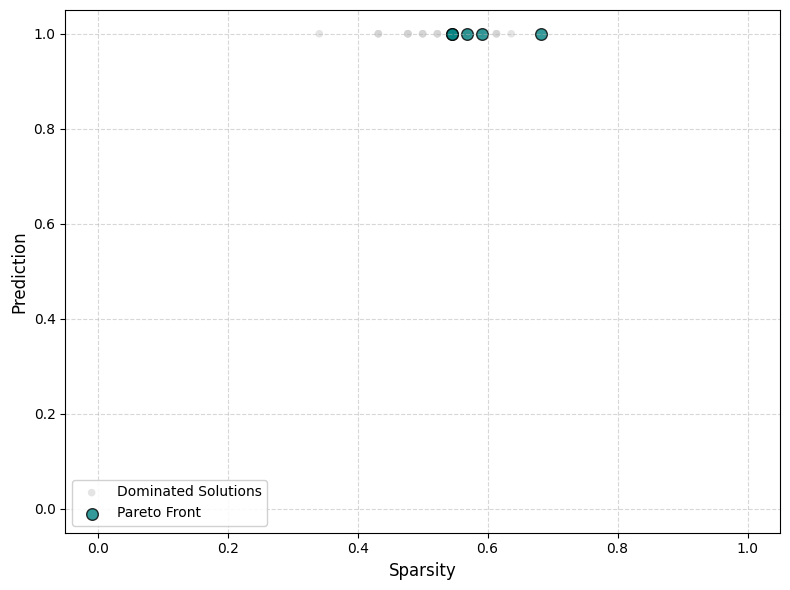

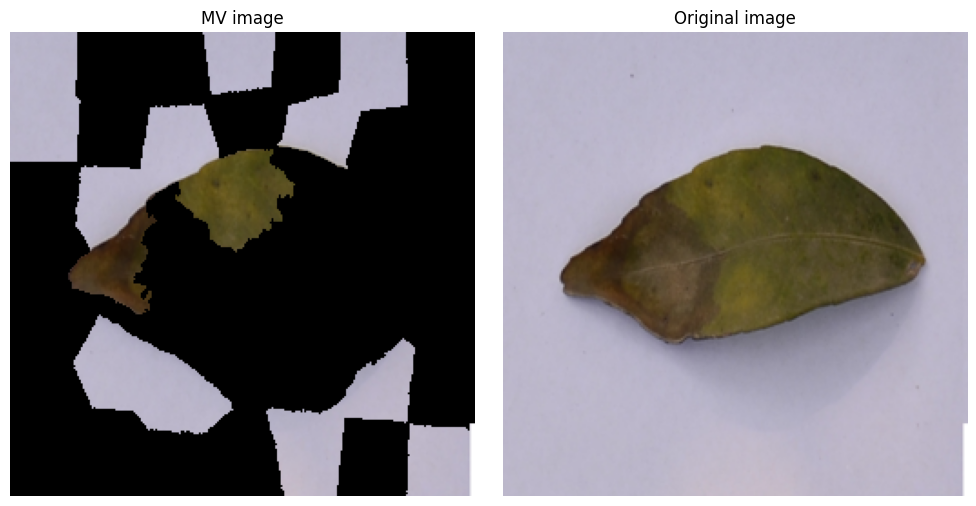


Hypervolume at 1th iteration: 0.7684
Hypervolume at 10th iteration: 1.0452


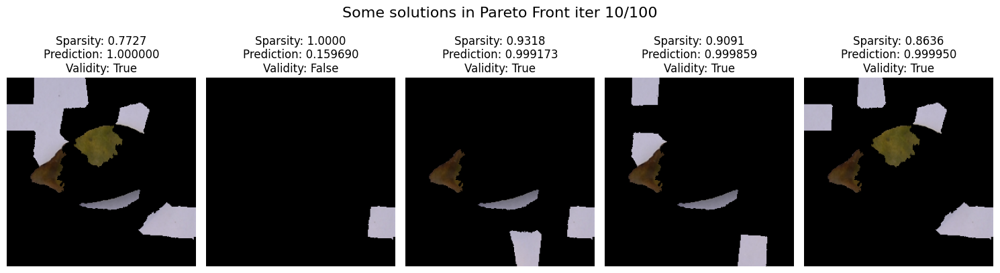

Pareto Front size: 7


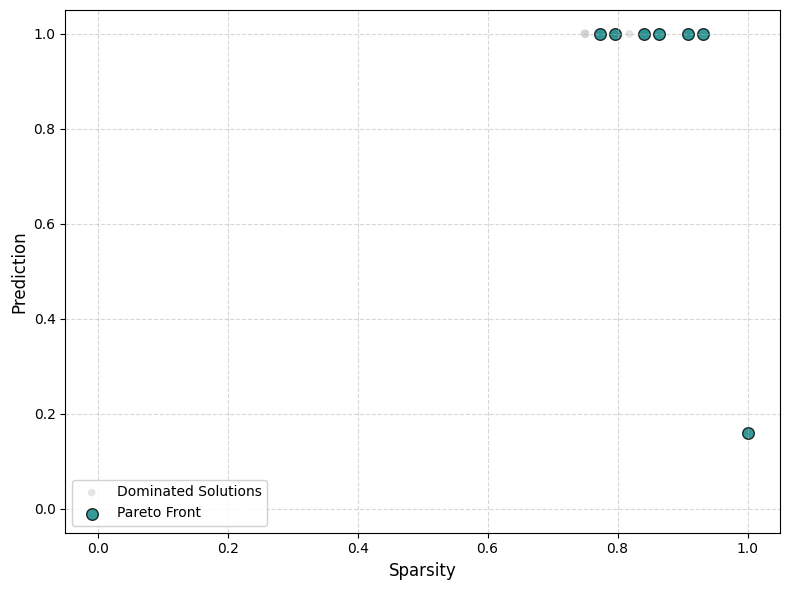

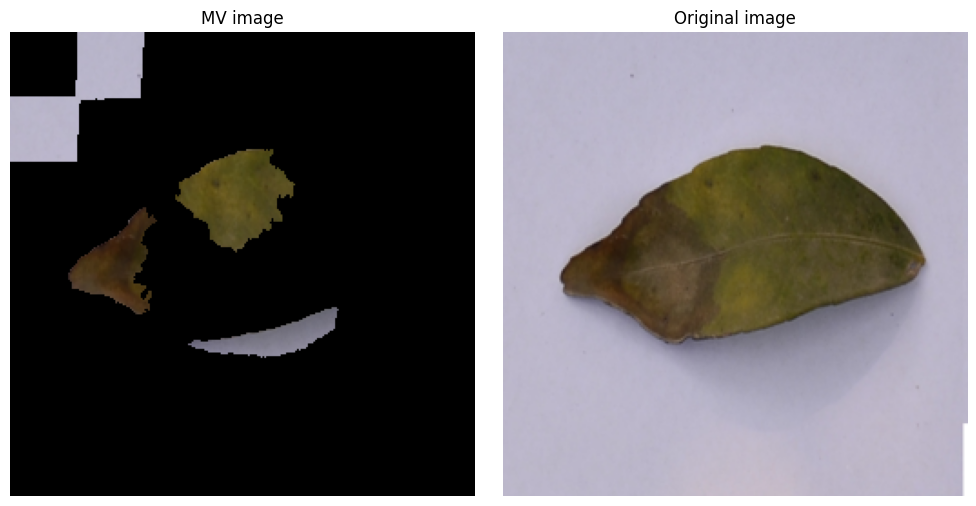


Hypervolume at 20th iteration: 1.0902


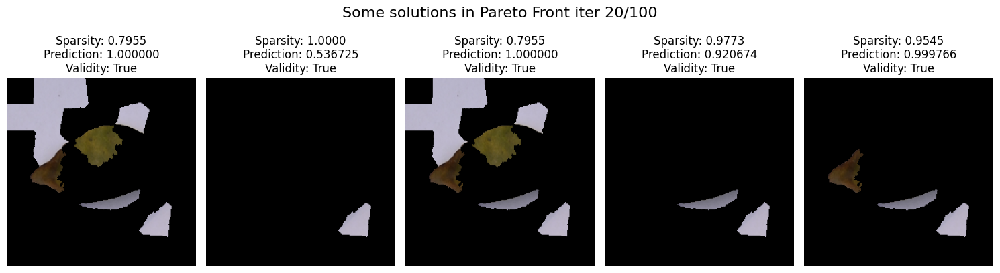

Pareto Front size: 35


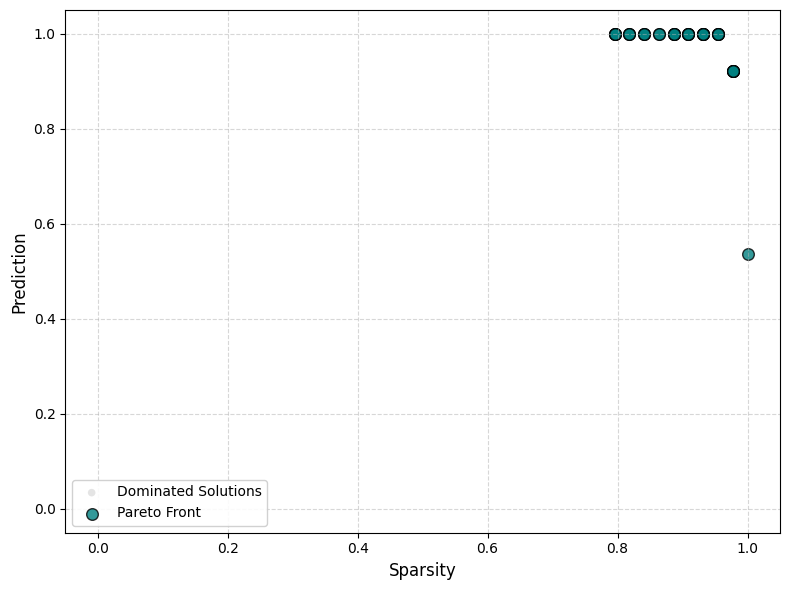

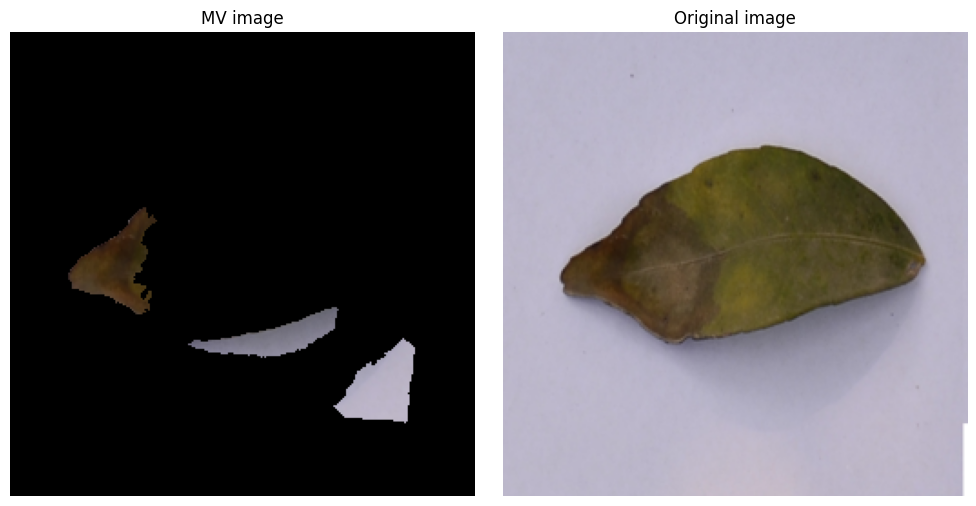


Hypervolume at 30th iteration: 1.1035


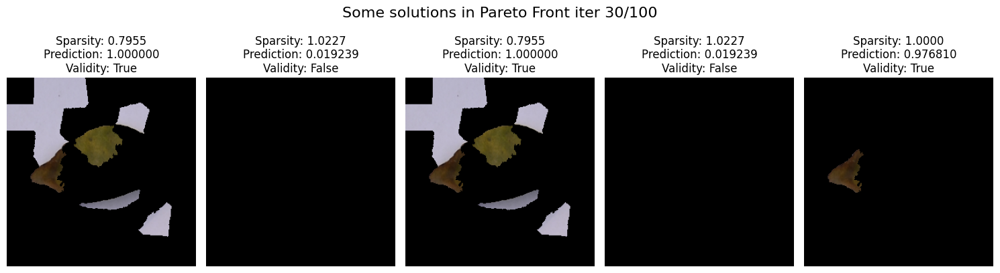

Pareto Front size: 35


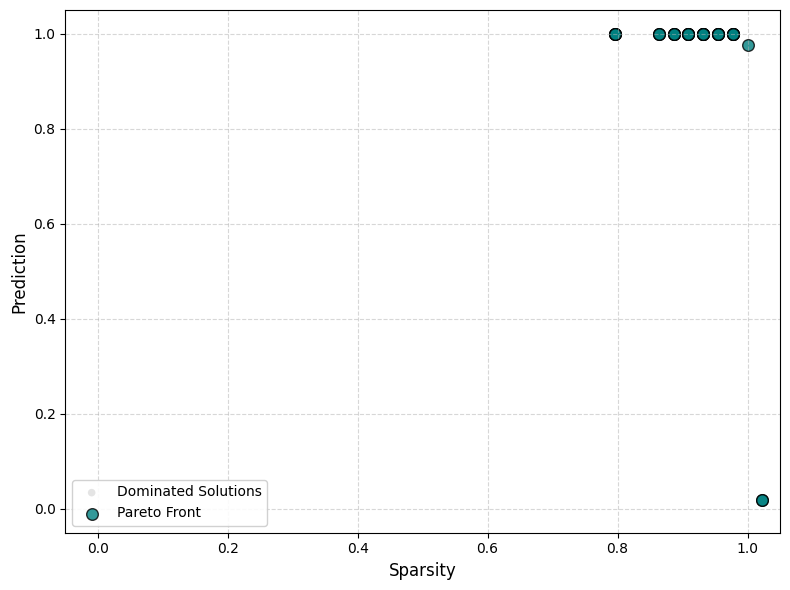

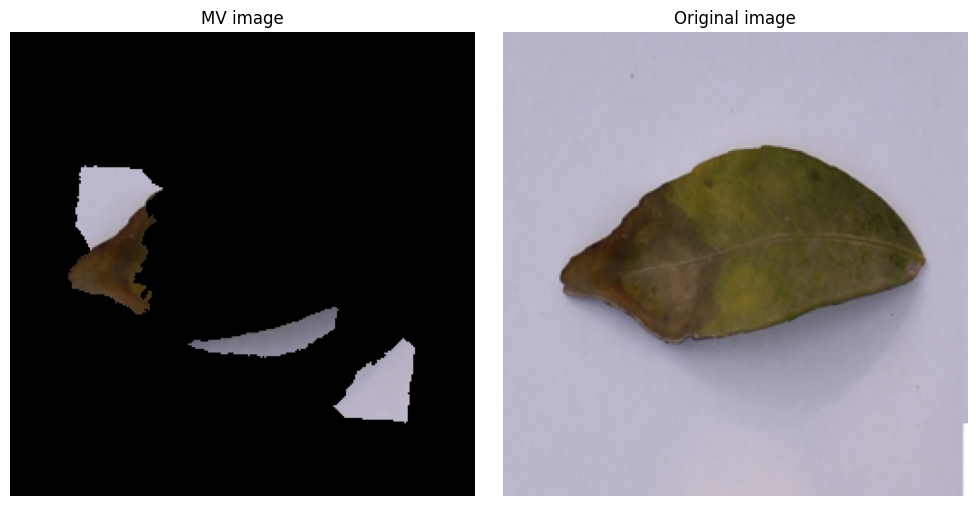


Hypervolume at 40th iteration: 1.1035


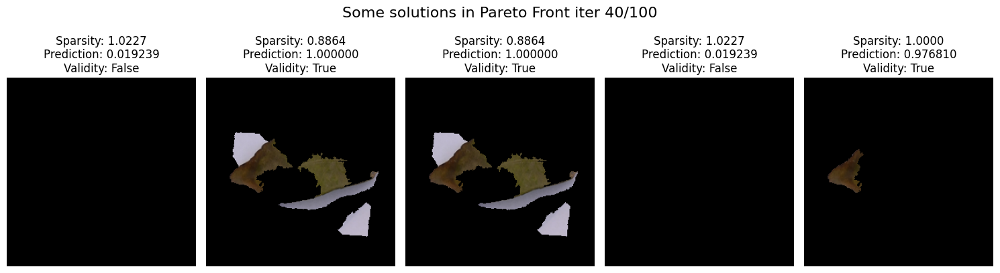

Pareto Front size: 35


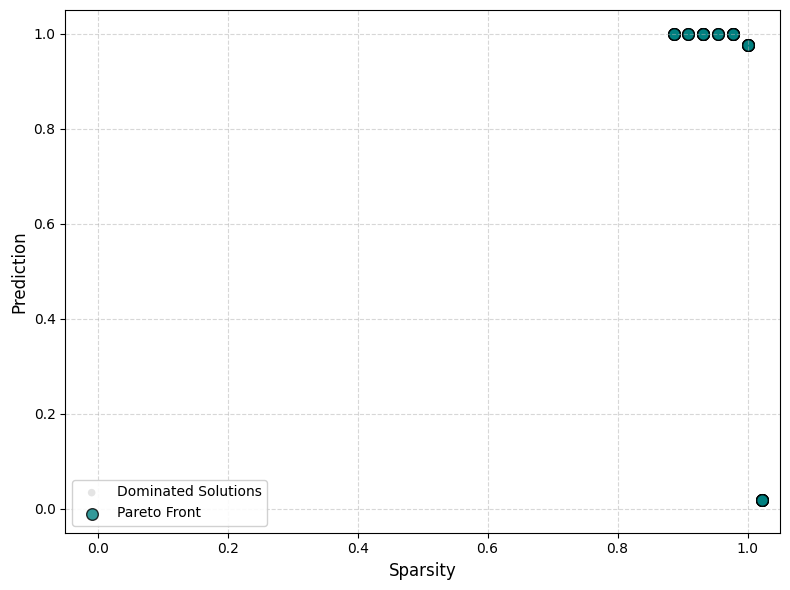

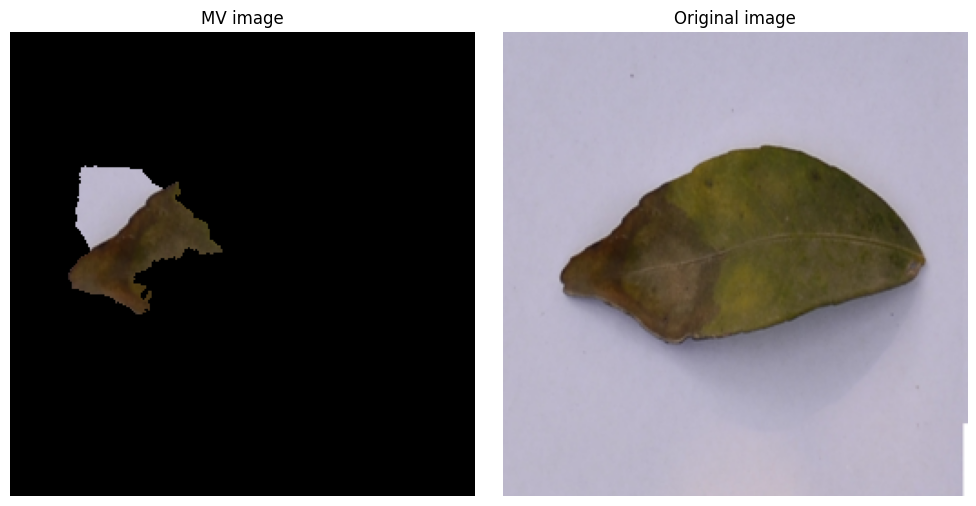


Hypervolume at 50th iteration: 1.1035


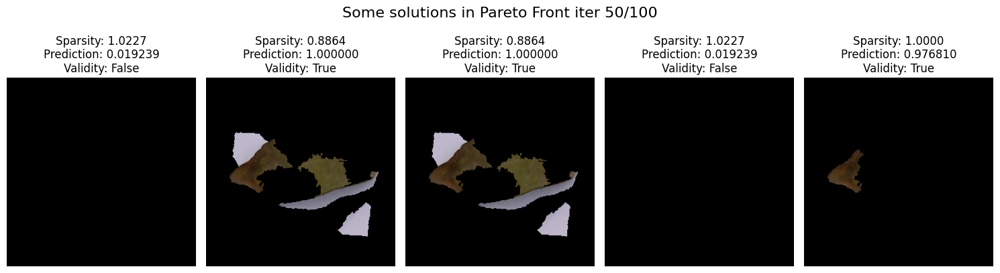

Pareto Front size: 35


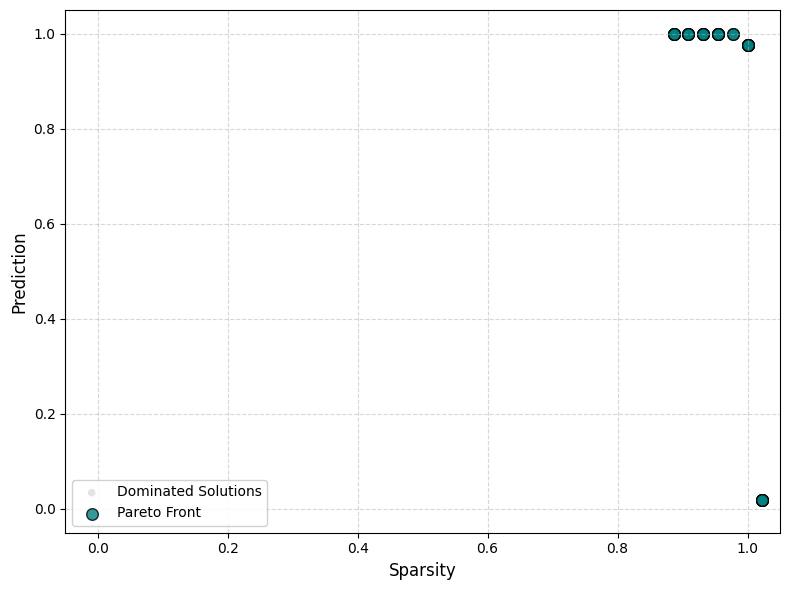

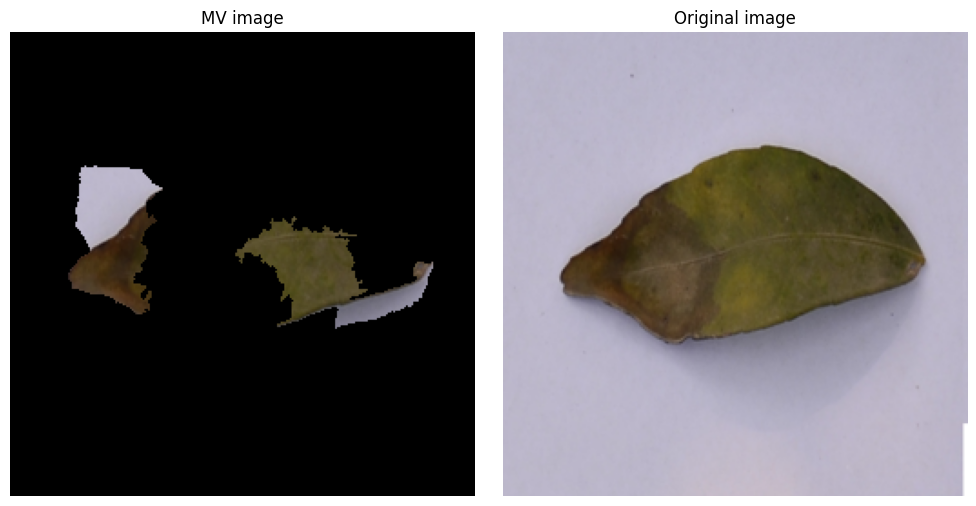


Hypervolume at 60th iteration: 1.1035


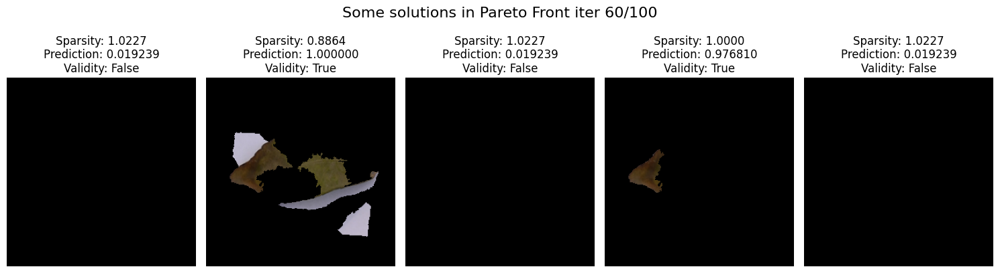

Pareto Front size: 35


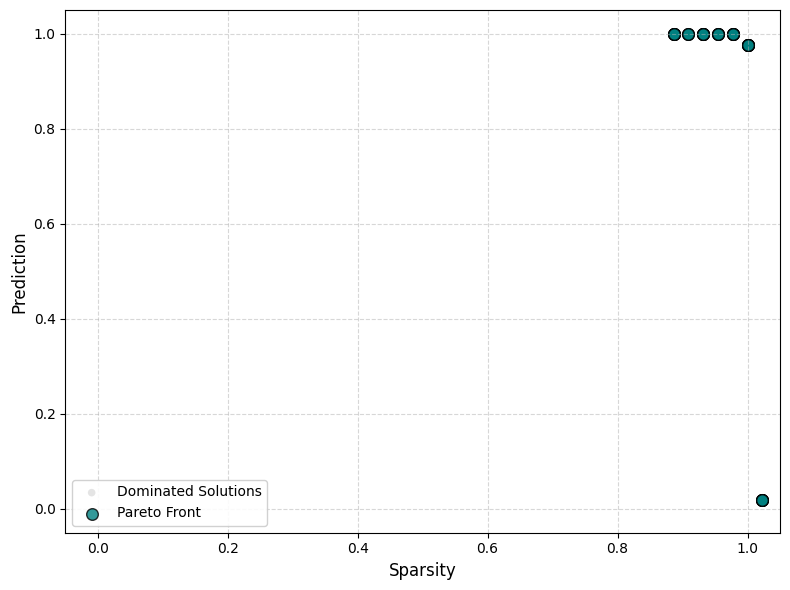

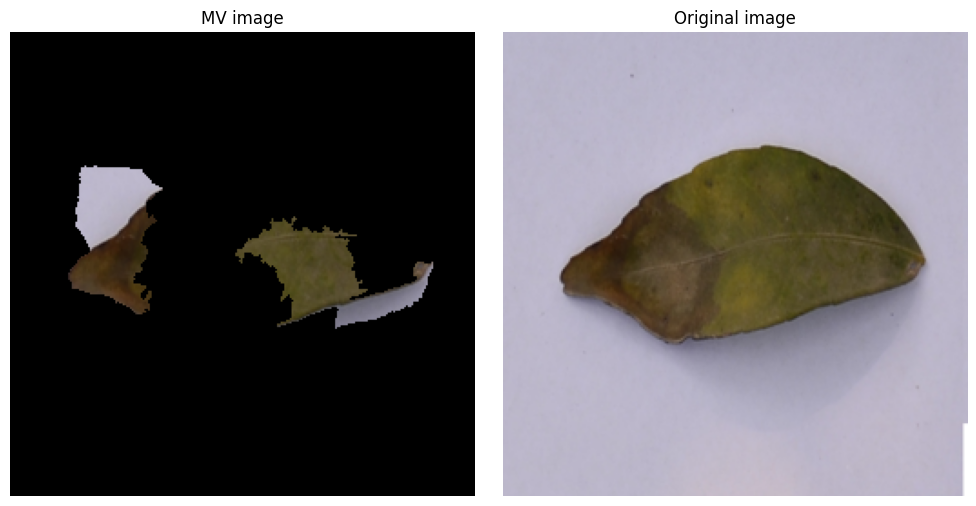


Hypervolume at 70th iteration: 1.1035


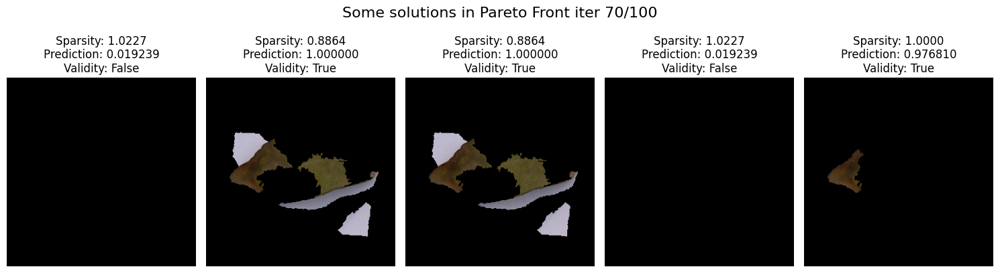

Pareto Front size: 35


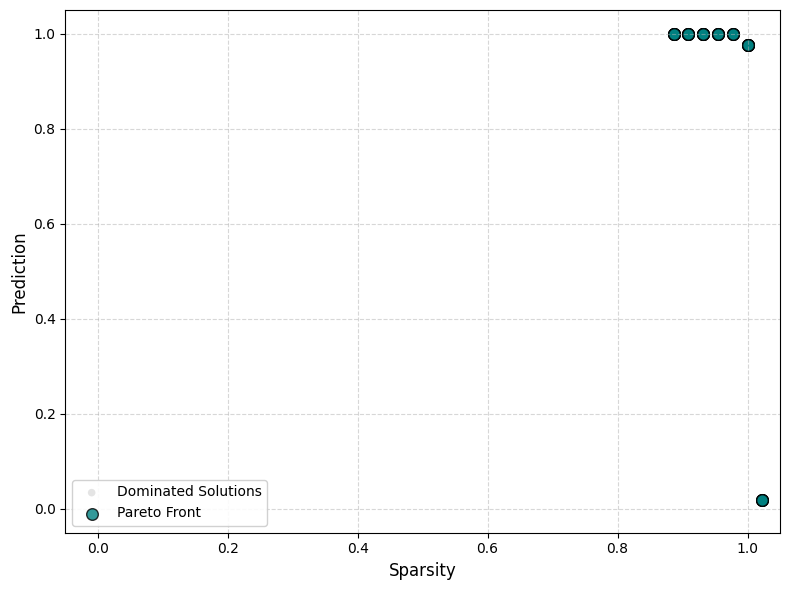

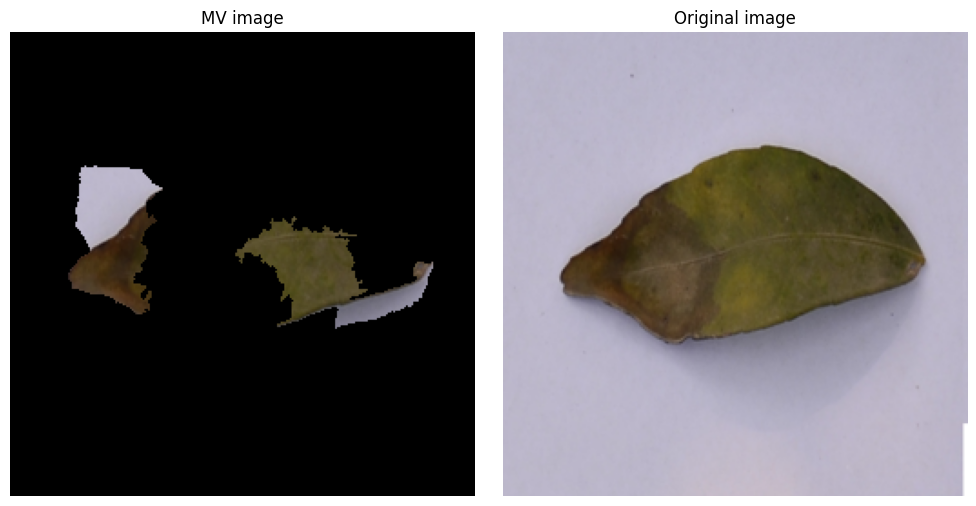


Hypervolume at 80th iteration: 1.1035


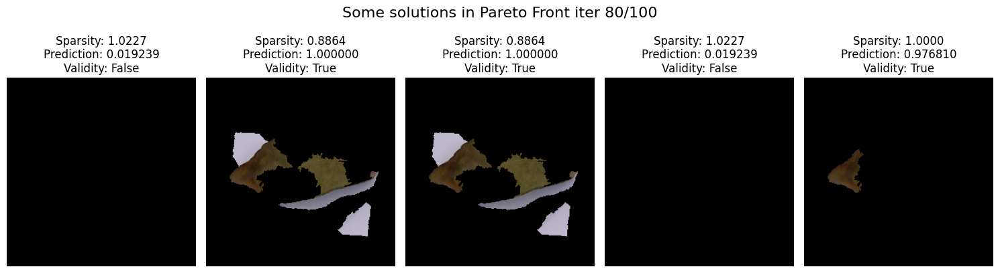

Pareto Front size: 35


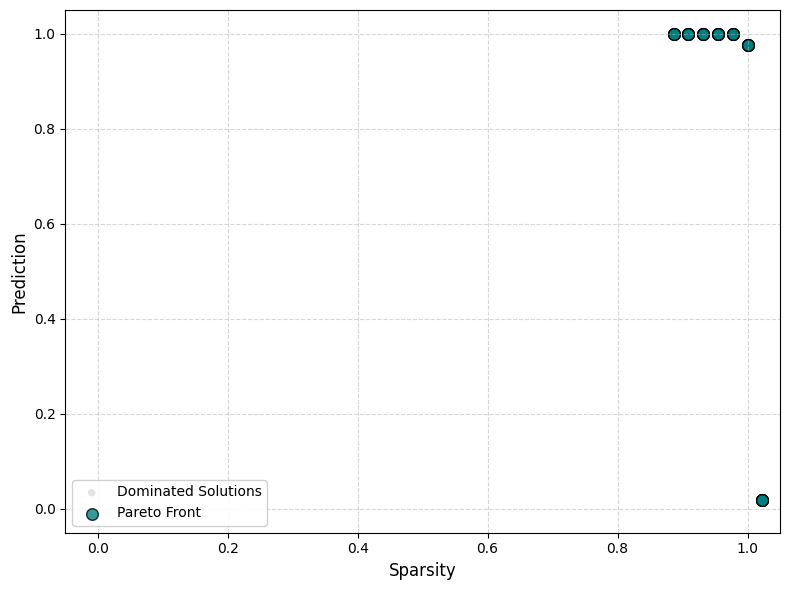

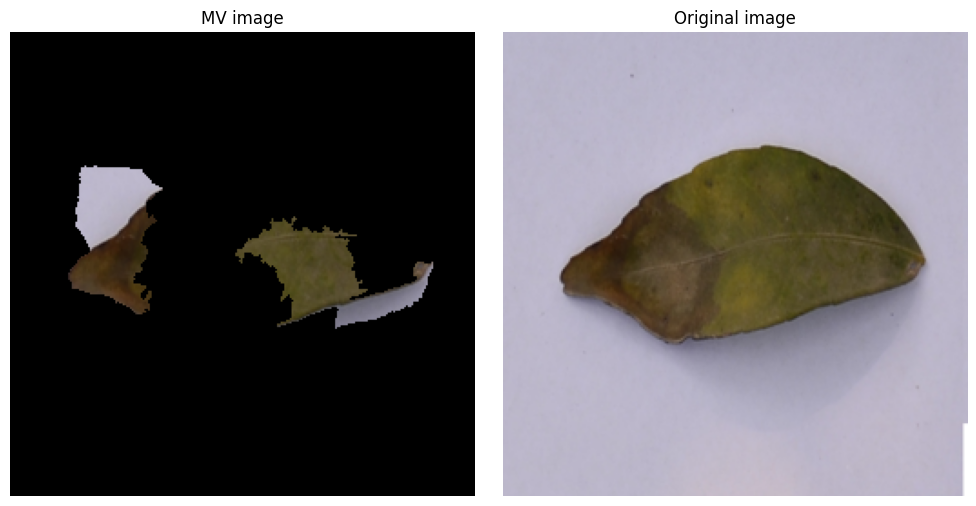


Hypervolume at 90th iteration: 1.1035


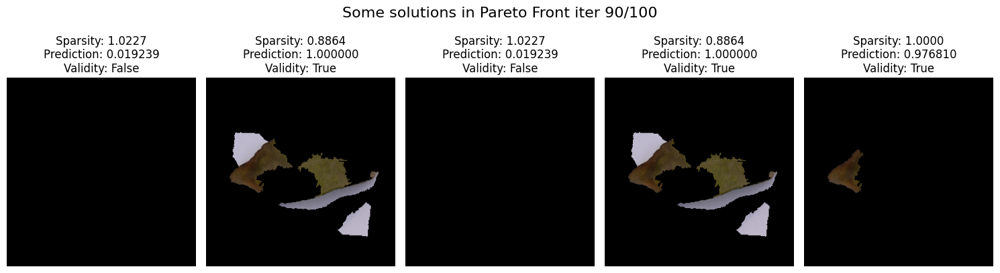

Pareto Front size: 35


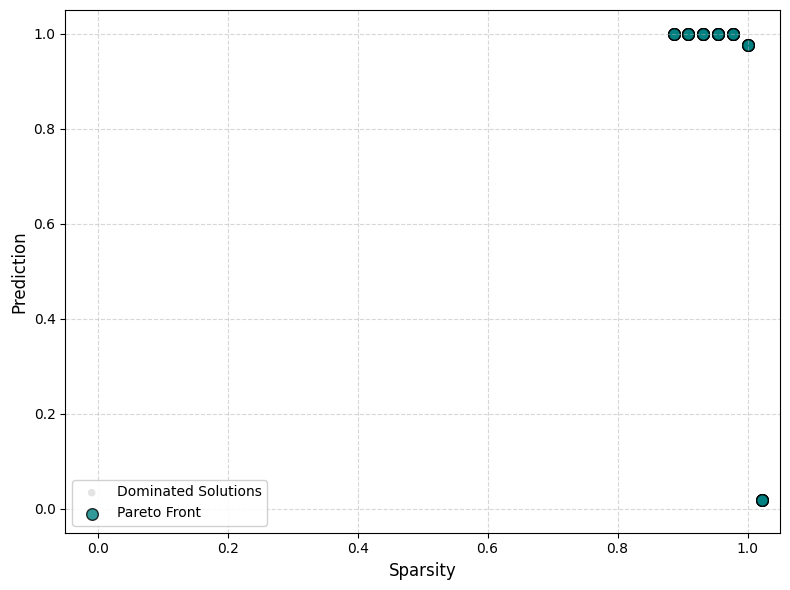

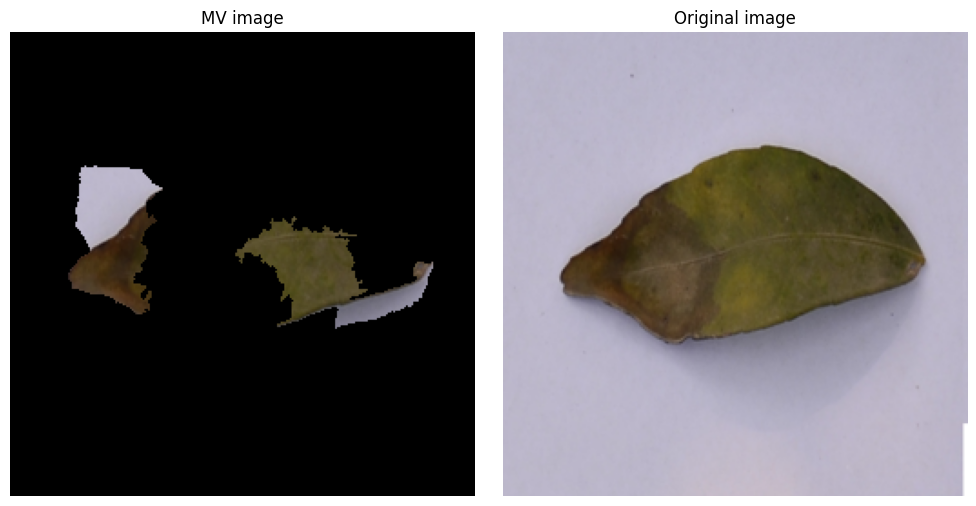


Hypervolume at 100th iteration: 1.1035


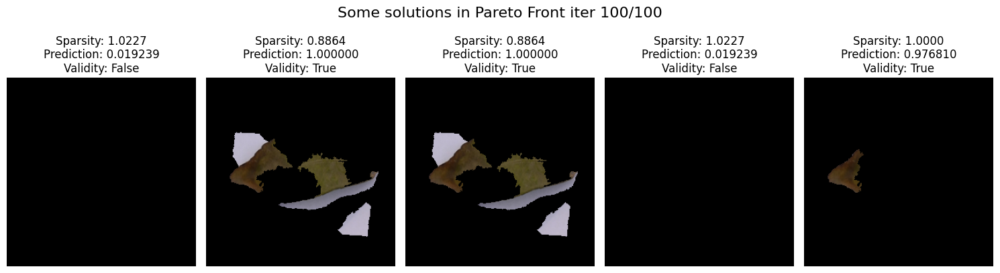

Pareto Front size: 35


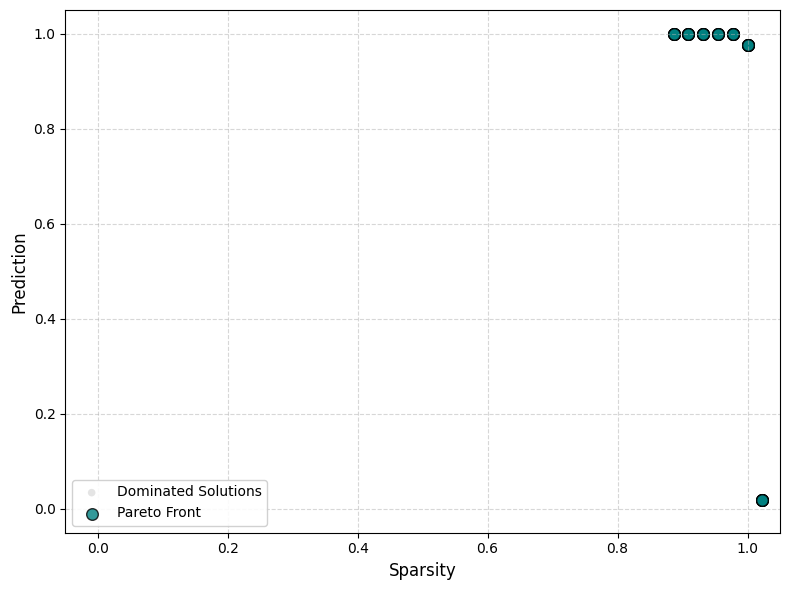

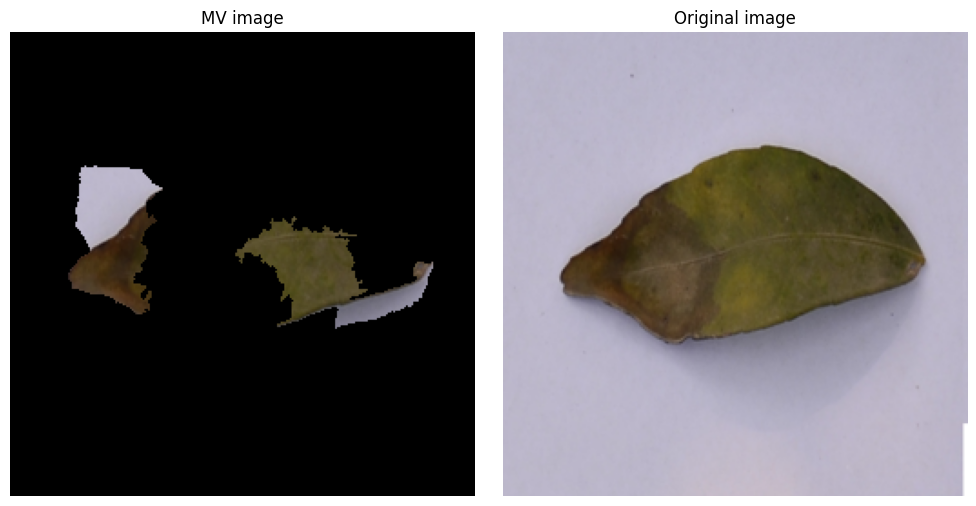

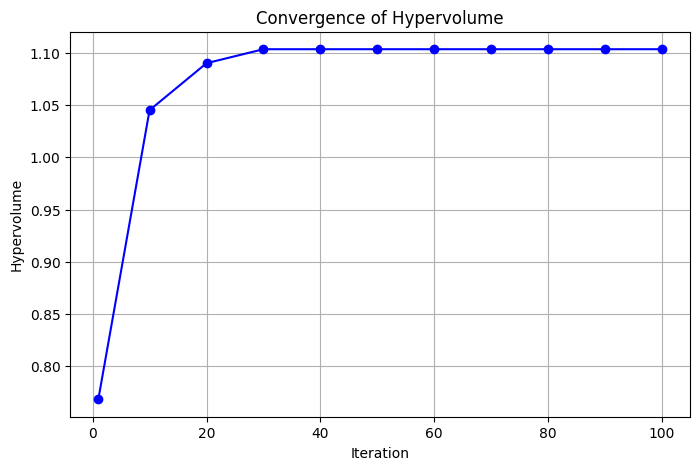

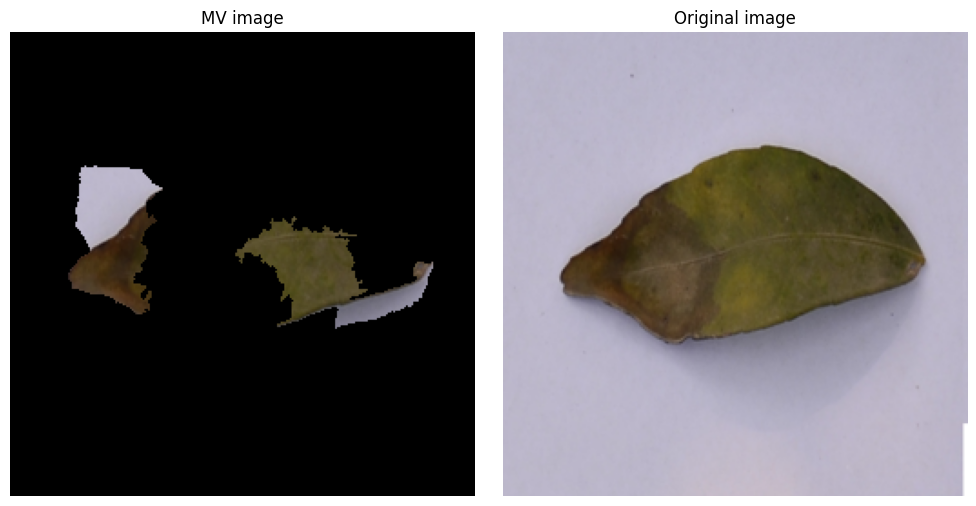

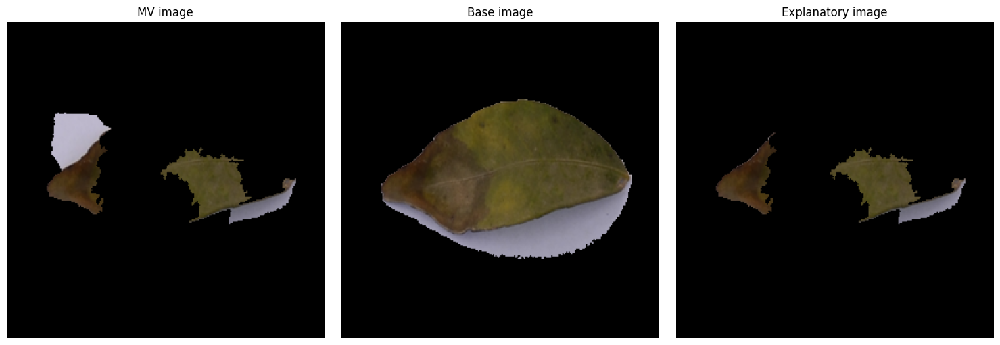

In [19]:
test_image = x_test[5]
label_vector = y_test[5]
label = np.where(label_vector == 1)[0].item()

actual = np.load("image5_delineated.npy")
worst = np.load("worst5.npy")

errors = []
explanations = []
explainers = []
for _ in range(3):
    normalized_error, explainer = run_pipeline(predict=predict_func,
                                                       test_image=test_image,
                                                       class_to_explain=label,
                                                       actual=actual,
                                                       worst=worst)
    errors.append(normalized_error)
    explanations.append(explainer.explanatory_image)
    explainers.append(explainer)

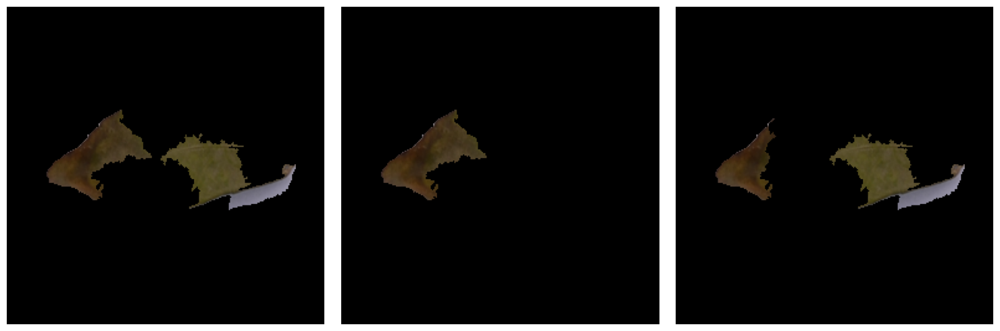

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, image in enumerate(explanations):
    ax[i].imshow(image)
    ax[i].axis("off")

plt.tight_layout()
plt.show()

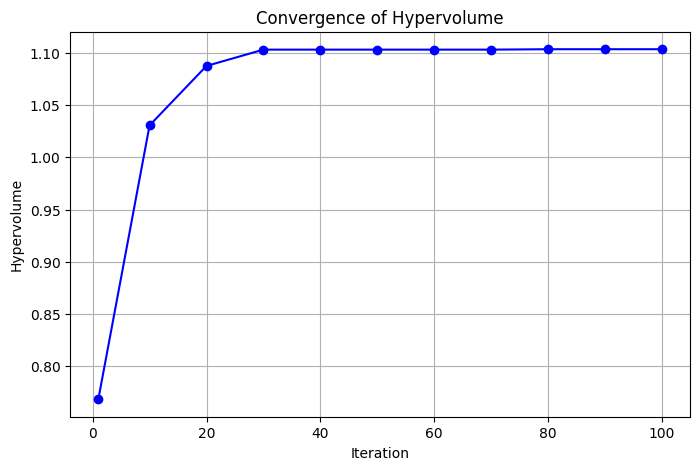

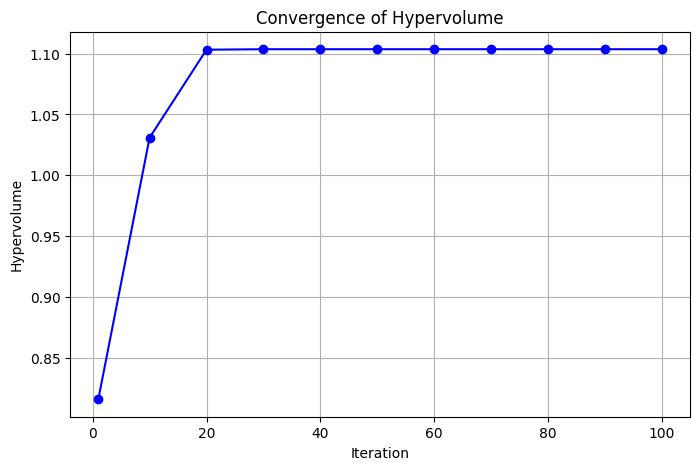

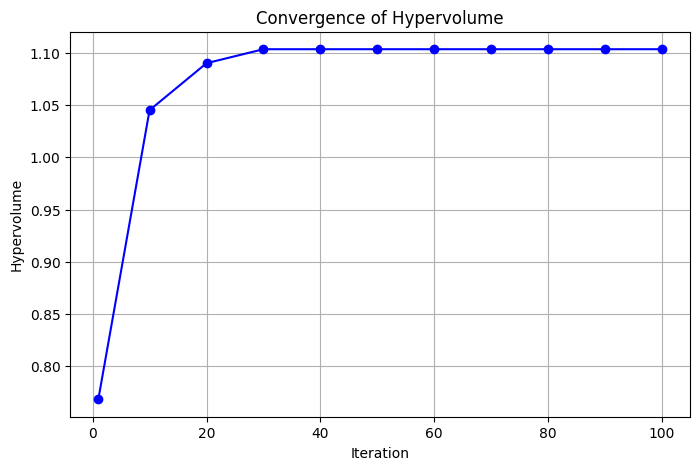

In [21]:
for i, explainer in enumerate(explainers):
    explainer.plot_hypervolume()
    plt.show()

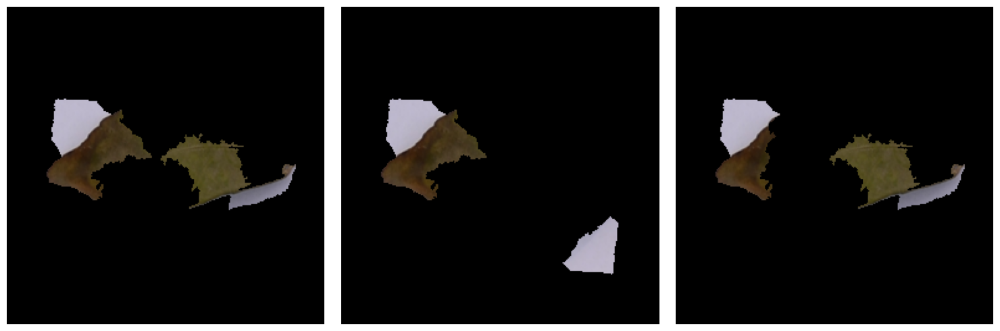

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, explainer in enumerate(explainers):
    ax[i].imshow(explainer.MV_solution.Image)
    ax[i].axis("off")

plt.tight_layout()

plt.savefig(f"{prefix}_MV.png", dpi=300, bbox_inches='tight')

plt.show()

In [23]:
def plot_paretofront(explainer, idx):
    optimal_solutions = []
    seen_chromosomes = set()

    for p in explainer.ParetoFront:
        if p.ValidAcc:
            chrom_tuple = tuple(p.Chromosome)
            if chrom_tuple not in seen_chromosomes:
                optimal_solutions.append(p)
                seen_chromosomes.add(chrom_tuple)

    optimal_solutions.sort(key=lambda x: x.Fitness[0])

    n = len(optimal_solutions)
    if n == 0:
        print("No optimal solution found.")
        return

    num_col = min(n, 5)
    num_row = (n - 1) // 5 + 1

    fig, axes = plt.subplots(num_row, num_col, figsize=(num_col*5, num_row*5), squeeze=False)

    k = 0
    for i in range(num_row):
        for j in range(num_col):
            if k < n:
                axes[i, j].imshow(optimal_solutions[k].Image)
                sparsity = optimal_solutions[k].Fitness[0]
                prediction = optimal_solutions[k].Fitness[1]
                axes[i, j].set_title(f"Sparsity: {sparsity:.4f}\nPrediction: {prediction:.6f}")
                k += 1

            axes[i, j].axis("off")

    plt.tight_layout()
    plt.savefig(f"{prefix}_paretofront_{idx}.png", dpi=300, bbox_inches='tight')
    plt.show()

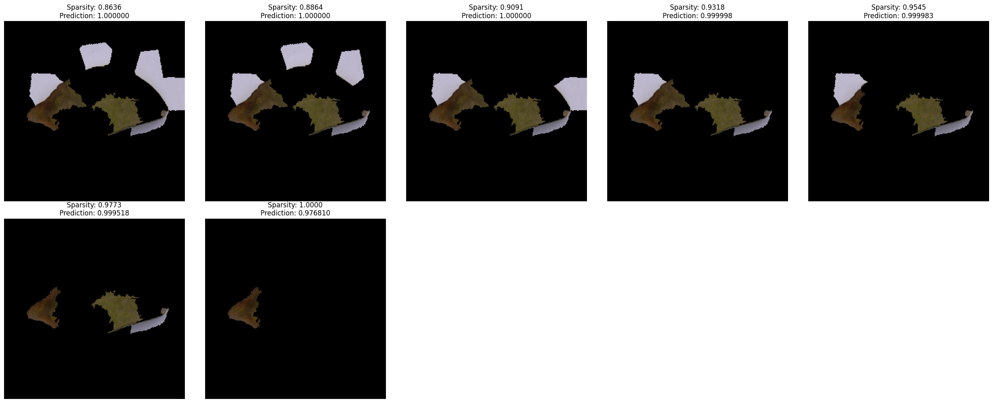

In [24]:
plot_paretofront(explainers[0], 0)

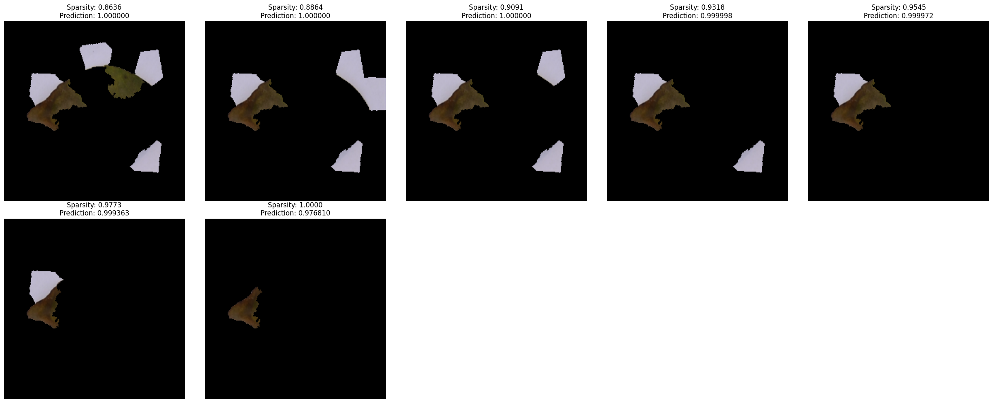

In [25]:
plot_paretofront(explainers[1], 1)

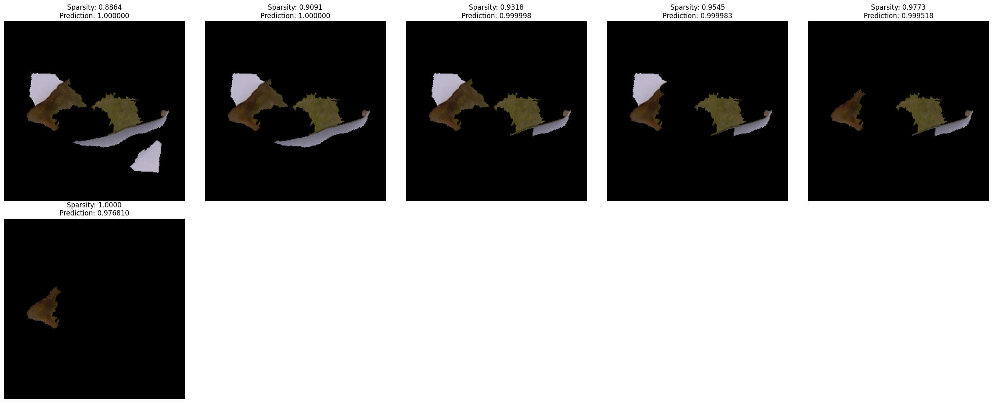

In [26]:
plot_paretofront(explainers[2], 2)

In [27]:
for i, explainer in enumerate(explainers):
    print(explainer.black_insertion_scores)
    print(explainer.black_deletion_scores)
    print(explainer.blur_insertion_scores)
    print(explainer.blur_deletion_scores)
    print()

    np.save(f"{prefix}_black_insertion_scores_{i}.npy", np.array(explainer.black_insertion_scores))
    np.save(f"{prefix}_black_deletion_scores_{i}.npy", np.array(explainer.black_deletion_scores))
    np.save(f"{prefix}_blur_insertion_scores_{i}.npy", np.array(explainer.blur_insertion_scores))
    np.save(f"{prefix}_blur_deletion_scores_{i}.npy", np.array(explainer.blur_deletion_scores))

[0.008330821990966797, 0.008418500423431396, -1.2516975402832031e-05, -1.2636184692382812e-05, -1.2636184692382812e-05, 1.728534698486328e-05, 0.011136472225189209, 0.002225518226623535, 0.00986403226852417, -1.2278556823730469e-05, -1.2040138244628906e-05, -1.239776611328125e-05, 4.780292510986328e-05, -1.1324882507324219e-05, -1.1682510375976562e-05, -1.1682510375976562e-05, -1.049041748046875e-05, -1.049041748046875e-05, 0.00016361474990844727, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -1.049041748046875e-05, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-06, -9.417533874511719e-

In [28]:
for i, explainer in enumerate(explainers):
    print(explainer.normalized_errors)
    np.save(f"{prefix}_normalizederrors_{i}.npy", np.array(explainer.normalized_errors))

[0.42383477091789246, 0.5089993476867676, 0.5380194783210754, 0.509688138961792, 0.5709884762763977, 0.37606796622276306, 0.31556493043899536, 0.3525860905647278, 0.3246632218360901, 0.3179779648780823, 0.32498979568481445, 0.36300894618034363, 0.286889910697937, 0.34611740708351135, 0.35905197262763977, 0.35905197262763977, 0.3205639123916626, 0.3205639123916626, 0.21770167350769043, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.3205639123916626, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572280884, 0.27320295572

In [29]:
for i, explainer in enumerate(explainers):
    print(explainer.iou_scores)
    np.save(f"{prefix}_iouscores_{i}.npy", np.array(explainer.iou_scores))

[0.005071205279610976, 0.003955138971663867, 0.10887309110057926, 0.11655000704655423, 0.05173519561034704, 0.16927483582506636, 0.08864947404139803, 0.07832408934192775, 0.08633509583608724, 0.2088768422835846, 0.18933150183150182, 0.17200499168053246, 0.11873508353221957, 0.11141283264799441, 0.1097691484482495, 0.1097691484482495, 0.12208808025845945, 0.12208808025845945, 0.15621811585987982, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.12208808025845945, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404275996, 0.13955296404

In [30]:
!zip -q results.zip {prefix}*.png {prefix}*.npy

files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>